# Superstore Retail Sales — Exploratory Data Analysis (EDA)

**Internship assignment: Datheon**  |  **Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

---

## 1. Project Introduction

This notebook performs a complete Exploratory Data Analysis on a Superstore retail sales dataset (orders from 2015 to 2018, United States).

**Workflow followed in this notebook**

| Step | What we do |
|---|---|
| 1 | Load the file and **inspect** it without assuming anything (columns, types, missing values, duplicates) |
| 2 | **Clean** it (stray rows, data types, missing values, duplicates, inconsistent text, outliers) |
| 3 | **Engineer features** (Year, Month, Quarter, Profit Margin, Discount Group, ...) |
| 4 | **Explore**: sales, customers, categories, regions, discounts, seasonality |
| 5 | **Visualise** with 10 required charts (+2 extra), each with a short business interpretation |
| 6 | Turn results into **business insights and recommendations** |
| 7 | **Export** the deliverables (cleaned CSV, PNG charts, PDF summary, insights file) |

Every number in this notebook is calculated directly from the uploaded file. Nothing is typed in by hand.

## 2. Business Problem

A retail company sells Furniture, Office Supplies and Technology products across four US regions. Management wants to know:

1. **How is the business performing** (sales, profit, growth)?
2. **Who buys** and how concentrated is our customer base?
3. **Which categories, products and regions** make or lose money?
4. **Do discounts hurt profit?**
5. **Is there a seasonal pattern** we can plan around?

The goal is to turn the raw data into clear, evidence-based recommendations.

## 3. Import Libraries

We load the libraries once, set a consistent chart style, and define a few small helper functions used later.

In [1]:
# Standard library
import os
import warnings

# Data handling
import numpy as np
import pandas as pd

# Plotting
import matplotlib
try:
    get_ipython()                  # this name exists only inside Jupyter
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
    matplotlib.use("Agg")          # no pop-up windows when run as a normal .py script
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns

# Pretty printing in Jupyter (plain print when run as a .py script)
if IN_NOTEBOOK:
    from IPython.display import display, Markdown
else:
    def display(obj):
        print(obj)
    def Markdown(text):
        return text

# ---- Global settings ----
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelsize": 11})

# Colours used in all charts (consistent look)
BLUE, GREEN, RED, ORANGE, GREY = "#2E5A88", "#2E8B57", "#C0392B", "#E08E0B", "#7F8C8D"

# ---- Output folders ----
OUTPUT_DIR = "outputs"
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# ---- Small helper functions ----
def money_k(x, pos=None):
    """Axis formatter: 125000 -> $125K"""
    return f"${x/1000:,.0f}K"

def fm(v):
    """Format a money value for sentences: 1234567 -> $1.23M, -135364 -> -$135.4K"""
    sign = "-" if v < 0 else ""
    v = abs(v)
    if v >= 1e6:
        return f"{sign}${v/1e6:,.2f}M"
    if v >= 1e3:
        return f"{sign}${v/1e3:,.1f}K"
    return f"{sign}${v:,.0f}"

def md_safe(text):
    """Escape $ so Jupyter does not treat two dollar signs as a maths formula."""
    return text.replace("$", r"\$")

def save_fig(filename):
    """Save the current chart as PNG, then show it (notebook) or close it (script)."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, filename), dpi=150, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close()

print("Libraries loaded. pandas", pd.__version__, "| numpy", np.__version__)

Libraries loaded. pandas 3.0.6 | numpy 2.5.4


## 4. Dataset Loading

The code looks for `superstore_sales.csv` in a few common places and stops with a clear message if it is missing. If the file is not UTF-8, it retries with a second encoding.

In [2]:
POSSIBLE_PATHS = [
    "superstore_sales.csv",
    "data/superstore_sales.csv",
    "/mnt/user-data/uploads/superstore_sales.csv",
]
DATA_PATH = next((p for p in POSSIBLE_PATHS if os.path.exists(p)), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "superstore_sales.csv not found. Put it in the same folder as this notebook "
        "(or in a 'data' folder) and run the cell again."
    )

try:
    raw_df = pd.read_csv(DATA_PATH)
except UnicodeDecodeError:
    raw_df = pd.read_csv(DATA_PATH, encoding="latin1")   # fallback for non-UTF-8 files

print(f"Loaded '{DATA_PATH}'  ->  {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")

Loaded 'superstore_sales.csv'  ->  10,800 rows x 21 columns


## 5. Data Inspection

We look at the **raw** file first, exactly as uploaded, before changing anything.

In [3]:
# First 10 rows
display(raw_df.head(10))

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164
5,6,CA-2015-115812,6/9/2015,6/14/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7.0,0.00,14.1694
6,7,CA-2015-115812,6/9/2015,6/14/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,OFF-AR-10002833,Office Supplies,Art,Newell 322,7.2800,4.0,0.00,1.9656
7,8,CA-2015-115812,6/9/2015,6/14/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.1520,6.0,0.20,90.7152
8,9,CA-2015-115812,6/9/2015,6/14/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,OFF-BI-10003910,Office Supplies,Binders,DXL Angle-View Binders with Locking Rings by S...,18.5040,3.0,0.20,5.7825
9,10,CA-2015-115812,6/9/2015,6/14/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,OFF-AP-10002892,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,114.9000,5.0,0.00,34.4700


In [4]:
# Last 5 rows
display(raw_df.tail(5))

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10795,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10796,Yes,US-2018-147998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10797,Yes,US-2018-151127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Shape, column names and data types
print("Shape (rows, columns):", raw_df.shape)
print("\nColumn names:")
for i, col in enumerate(raw_df.columns, start=1):
    print(f"  {i:>2}. {col}")

print("\nData types:")
display(raw_df.dtypes.to_frame("dtype"))

Shape (rows, columns): (10800, 21)

Column names:
   1. Row ID
   2. Order ID
   3. Order Date
   4. Ship Date
   5. Ship Mode
   6. Customer ID
   7. Customer Name
   8. Segment
   9. Country
  10. City
  11. State
  12. Postal Code
  13. Region
  14. Product ID
  15. Category
  16. Sub-Category
  17. Product Name
  18. Sales
  19. Quantity
  20. Discount
  21. Profit

Data types:


,dtype
Row ID,str
Order ID,str
Order Date,str
Ship Date,str
Ship Mode,str
Customer ID,str
Customer Name,str
Segment,str
Country,str
City,str


In [6]:
# Statistical summary: numeric columns, then text columns
numeric_cols = raw_df.select_dtypes(include="number").columns.tolist()
text_cols = [c for c in raw_df.columns if c not in numeric_cols]

print("Numeric columns:")
display(raw_df[numeric_cols].describe().T)

print("Text columns:")
display(raw_df[text_cols].describe().T)

Numeric columns:


,count,mean,std,min,25%,50%,75%,max
Postal Code,9983.0,55245.233297,32038.715955,1040.000,23223.00000,57103.0000,90008.000,99301.000
Sales,9994.0,229.858001,623.245101,0.444,17.28000,54.4900,209.940,22638.480
Quantity,9994.0,3.789574,2.225110,1.000,2.00000,3.0000,5.000,14.000
Discount,9994.0,0.156203,0.206452,0.000,0.00000,0.2000,0.200,0.800
Profit,9994.0,28.656896,234.260108,-6599.978,1.72875,8.6665,29.364,8399.976


Text columns:


,count,unique,top,freq
Row ID,10800,10001,Yes,800
Order ID,10800,5015,CA-2018-100111,28
Order Date,9994,1236,9/5/2017,38
Ship Date,9994,1334,12/16/2016,35
Ship Mode,9994,4,Standard Class,5968
Customer ID,9994,793,WB-21850,37
Customer Name,9994,793,William Brown,37
Segment,9994,3,Consumer,5191
Country,9994,1,United States,9994
City,9994,531,New York City,915


In [7]:
# Missing values and duplicates
missing = raw_df.isna().sum()
missing_table = pd.DataFrame({"Missing": missing, "Missing (%)": (missing / len(raw_df) * 100).round(2)})
print("Missing values per column:")
display(missing_table[missing_table["Missing"] > 0])

print("Fully duplicated rows:", raw_df.duplicated().sum())

Missing values per column:


,Missing,Missing (%)
Order Date,806,7.46
Ship Date,806,7.46
Ship Mode,806,7.46
Customer ID,806,7.46
Customer Name,806,7.46
Segment,806,7.46
Country,806,7.46
City,806,7.46
State,806,7.46
Postal Code,817,7.56


Fully duplicated rows: 504


In [8]:
# Unique values in the categorical (text) columns
for col in text_cols:
    values = raw_df[col].dropna().unique()
    if len(values) <= 20:
        print(f"{col}  ({len(values)} unique): {sorted(map(str, values))}")
    else:
        print(f"{col}  ({len(values)} unique): too many to list, e.g. {list(map(str, values[:4]))}")

Row ID  (10001 unique): too many to list, e.g. ['1', '2', '3', '4']
Order ID  (5015 unique): too many to list, e.g. ['CA-2017-152156', 'CA-2017-138688', 'US-2016-108966', 'CA-2015-115812']
Order Date  (1236 unique): too many to list, e.g. ['11/8/2017', '6/12/2017', '10/11/2016', '6/9/2015']
Ship Date  (1334 unique): too many to list, e.g. ['11/11/2017', '6/16/2017', '10/18/2016', '6/14/2015']
Ship Mode  (4 unique): ['First Class', 'Same Day', 'Second Class', 'Standard Class']
Customer ID  (793 unique): too many to list, e.g. ['CG-12520', 'DV-13045', 'SO-20335', 'BH-11710']
Customer Name  (793 unique): too many to list, e.g. ['Claire Gute', 'Darrin Van Huff', "Sean O'Donnell", 'Brosina Hoffman']
Segment  (3 unique): ['Consumer', 'Corporate', 'Home Office']
Country  (1 unique): ['United States']
City  (531 unique): too many to list, e.g. ['Henderson', 'Los Angeles', 'Fort Lauderdale', 'Concord']
State  (49 unique): too many to list, e.g. ['Kentucky', 'California', 'Florida', 'North Carol

### What the inspection tells us

* The file has **10,800 rows x 21 columns**, but `Row ID` is read as *text*, which is unusual for an ID counter. Something non-numeric is hiding in it.
* **806 rows are empty in every business column** (Order Date, Sales, Profit, ...). That is also why those columns show 806 missing values.
* The `tail()` shows why: the bottom of the file contains rows with `Yes` in `Row ID` and only an Order ID. Other sheets of the original workbook (a *People* table and a *Returns* table) were appended to the sales table when the CSV was exported.
* The "504 duplicate rows" are all inside that appended block (the Returns table repeats an Order ID once per item). They are **not** real duplicate sales.
* After the stray rows are set aside, the only remaining gap is **Postal Code** (11 rows).
* The categorical columns (Segment, Region, Category, Ship Mode, ...) look tidy on the surface. We still verify them in the cleaning step.

None of the stray rows is a sale, so removing them from the sales table is not deleting business data. We will keep the useful part (the list of **returned orders**) and use it later.

## 6. Data Cleaning

Each step below explains **what** we do and **why**. We work on a copy (`df`) so `raw_df` stays untouched.

### 6.1 Standardise column names and confirm required columns
The code matches columns ignoring upper/lower case, spaces and symbols, so `order_date` or `Order Date` both work. It never assumes a column exists without checking.

In [9]:
# From here on, show numbers with thousands separators and 2 decimals (the raw inspection above used pandas defaults)
pd.set_option("display.float_format", "{:,.2f}".format)

df = raw_df.copy()

EXPECTED = ["Row ID", "Order ID", "Order Date", "Ship Date", "Ship Mode", "Customer ID", "Customer Name",
            "Segment", "Country", "City", "State", "Postal Code", "Region", "Product ID", "Category",
            "Sub-Category", "Product Name", "Sales", "Quantity", "Discount", "Profit"]

def normalise(name):
    """'Order_Date ' -> 'orderdate'"""
    return "".join(ch for ch in str(name).lower() if ch.isalnum())

lookup = {normalise(c): c for c in EXPECTED}
df.columns = [lookup.get(normalise(c), str(c).strip()) for c in df.columns]

# Core columns the analysis needs. Stop early with a clear message if one is missing.
REQUIRED = ["Order ID", "Order Date", "Customer ID", "Customer Name", "Segment", "Category",
            "Sub-Category", "Region", "State", "Sales", "Quantity", "Discount", "Profit"]
missing_required = [c for c in REQUIRED if c not in df.columns]
if missing_required:
    raise KeyError(f"Required columns not found in the file: {missing_required}")

optional_missing = [c for c in EXPECTED if c not in df.columns]
print("All required columns found.")
print("Optional columns not present:", optional_missing if optional_missing else "none")

All required columns found.
Optional columns not present: none


### 6.2 Separate the stray rows (appended *People* and *Returns* tables)
**Why:** a real sale always has a numeric `Row ID`. Rows that do not are not sales, so they would distort every count and average.
**How:** we identify them, prove they hold no sales data, and extract the one useful piece: the list of returned Order IDs.

In [10]:
# A real transaction has a numeric Row ID
is_transaction = pd.to_numeric(df["Row ID"], errors="coerce").notna()
stray_rows = df.loc[~is_transaction].copy()
print(f"Rows in file: {len(df):,} | real transactions: {is_transaction.sum():,} | stray rows: {len(stray_rows):,}")

# Prove the stray rows contain no sales data
business_cols = [c for c in df.columns if c not in ["Row ID", "Order ID"]]
print("Stray rows holding data in any business column:", stray_rows[business_cols].notna().any(axis=1).sum())

# A few examples
display(stray_rows[["Row ID", "Order ID"]].iloc[[0, 1, 5, 6, 7]])

Rows in file: 10,800 | real transactions: 9,994 | stray rows: 806
Stray rows holding data in any business column: 0


,Row ID,Order ID
9994,Person,Region
9995,Anna Andreadi,West
9999,Returned,Order ID
10000,Yes,CA-2015-100762
10001,Yes,CA-2015-100762


In [11]:
# Extract the useful information from the appended tables
# (a) Returns table: rows where "Row ID" == "Yes" and "Order ID" holds the returned order
is_return_row = stray_rows["Row ID"].astype(str).str.strip().str.lower().eq("yes")
returned_orders = set(stray_rows.loc[is_return_row, "Order ID"].dropna().astype(str).str.strip())

# (b) People table: rows whose "Order ID" is actually a region name
valid_regions = set(df.loc[is_transaction, "Region"].dropna().unique())
people_table = (stray_rows.loc[stray_rows["Order ID"].isin(valid_regions), ["Row ID", "Order ID"]]
                .rename(columns={"Row ID": "Person", "Order ID": "Region"}))

print(f"Returns rows: {is_return_row.sum()}  ->  {len(returned_orders)} unique returned Order IDs")
print("Returned Order IDs that exist in the sales data:",
      len(returned_orders & set(df.loc[is_transaction, "Order ID"])), "of", len(returned_orders))
print("\nPeople table found in the file:")
display(people_table)

# Keep only the real transactions
df = df.loc[is_transaction].copy()
print(f"\nSales table now has {len(df):,} rows.")

Returns rows: 800  ->  296 unique returned Order IDs
Returned Order IDs that exist in the sales data: 296 of 296

People table found in the file:


,Person,Region
9995,Anna Andreadi,West
9996,Chuck Magee,East
9997,Kelly Williams,Central
9998,Cassandra Brandow,South



Sales table now has 9,994 rows.


### 6.3 Correct data types
| Column | Problem | Fix |
|---|---|---|
| `Row ID` | text | integer |
| `Order Date`, `Ship Date` | text like `11/8/2017` | real `datetime` (month/day/year) |
| `Postal Code` | float (`42420.0`), and leading zeros would be lost | 5-character text (ZIP codes are identifiers, not numbers to add up) |
| `Sales`, `Quantity`, `Discount`, `Profit` | must be numeric | converted with `to_numeric`; anything unreadable becomes missing so we can see it |

In [12]:
# Row ID -> integer
df["Row ID"] = pd.to_numeric(df["Row ID"]).astype(int)

# Dates -> datetime
def parse_dates(series):
    """Try month/day/year first; if some values do not fit, let pandas guess."""
    parsed = pd.to_datetime(series, format="%m/%d/%Y", errors="coerce")
    if parsed.isna().sum() > series.isna().sum():
        parsed = pd.to_datetime(series, errors="coerce")
    return parsed

for col in ["Order Date", "Ship Date"]:
    if col in df.columns:
        before_missing = df[col].isna().sum()
        df[col] = parse_dates(df[col])
        print(f"{col}: parsed. Unreadable dates: {df[col].isna().sum() - before_missing}")

# Numbers -> numeric
for col in ["Sales", "Quantity", "Discount", "Profit"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Postal code -> 5-digit text
if "Postal Code" in df.columns:
    df["Postal Code"] = df["Postal Code"].astype("Int64").astype("string").str.zfill(5)

print("\nOrder dates range from", df["Order Date"].min().date(), "to", df["Order Date"].max().date())
display(df.dtypes.to_frame("dtype").T)

Order Date: parsed. Unreadable dates: 0
Ship Date: parsed. Unreadable dates: 0

Order dates range from 2015-01-03 to 2018-12-30


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
dtype,int64,str,datetime64[us],datetime64[us],str,str,str,str,str,str,str,string,str,str,str,str,str,float64,float64,float64,float64


### 6.4 Handle missing values
**Rule we follow:** never delete a valid sale just because a *descriptive* field is empty. We only drop a row if a field that is essential for analysis (date, customer, Sales, Profit...) is missing. Otherwise we fill with a justified value.

In [13]:
missing_now = df.isna().sum()
print("Missing values after removing the stray rows:")
display(missing_now[missing_now > 0].to_frame("Missing"))

print("Which places are the missing Postal Codes from?")
display(df.loc[df["Postal Code"].isna(), ["City", "State"]].value_counts().to_frame("rows"))

Missing values after removing the stray rows:


,Missing
Postal Code,11


Which places are the missing Postal Codes from?


,,rows
City,State,
Burlington,Vermont,11


In [14]:
# (a) Essential columns: drop the row only if one of these is missing (none expected)
essential = ["Order ID", "Order Date", "Customer ID", "Category", "Region", "Sales", "Profit"]
rows_before = len(df)
df = df.dropna(subset=essential)
print(f"Rows dropped because an essential field was missing: {rows_before - len(df)}")

# (b) Postal Code: all missing values are Burlington, Vermont, and no other Burlington (VT) row has a code.
#     We fill them with Burlington VT's real ZIP code, 05401 (outside knowledge, flagged here for transparency).
#     Postal Code is not used in any calculation, so this cannot change a metric.
is_burlington_vt = df["City"].eq("Burlington") & df["State"].eq("Vermont")
fill_mask = df["Postal Code"].isna() & is_burlington_vt
df.loc[fill_mask, "Postal Code"] = "05401"
print(f"Postal Codes filled for Burlington, VT: {fill_mask.sum()}")

# (c) Safety net for anything else still missing (does nothing on this file)
for col in df.columns:
    n_missing = df[col].isna().sum()
    if n_missing == 0:
        continue
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())          # numbers -> median (not affected by outliers)
    elif pd.api.types.is_datetime64_any_dtype(df[col]):
        pass                                                 # leave missing dates as they are
    else:
        df[col] = df[col].fillna("Unknown")                  # text -> "Unknown"
    print(f"  Filled {n_missing} missing values in '{col}'")

# Quantity is a whole number of items
df["Quantity"] = df["Quantity"].astype(int)
print("\nMissing values left:", int(df.isna().sum().sum()))

Rows dropped because an essential field was missing: 0
Postal Codes filled for Burlington, VT: 11

Missing values left: 0


### 6.5 Detect and remove duplicates
`Row ID` is just a counter, so two lines that are identical in **every other column** (same order, product, quantity, price, discount, profit) are a duplicated entry even though their Row IDs differ.

In [15]:
print("Duplicate Row IDs:", df["Row ID"].duplicated().sum())

content_cols = [c for c in df.columns if c != "Row ID"]
dup_rows = df[df.duplicated(subset=content_cols, keep=False)]
print("Rows involved in content-duplicates:", len(dup_rows))
display(dup_rows[["Row ID", "Order ID", "Customer Name", "Product Name", "Sales", "Quantity", "Discount", "Profit"]])

rows_before = len(df)
sales_before = df["Sales"].sum()
df = df.drop_duplicates(subset=content_cols, keep="first").reset_index(drop=True)
print(f"\nRemoved {rows_before - len(df)} duplicate row(s), worth {fm(sales_before - df['Sales'].sum())} of sales "
      f"({(sales_before - df['Sales'].sum()) / sales_before * 100:.3f}% of total). Rows now: {len(df):,}")

Duplicate Row IDs: 0
Rows involved in content-duplicates: 2


,Row ID,Order ID,Customer Name,Product Name,Sales,Quantity,Discount,Profit
3405,3406,US-2015-150119,Laurel Beltran,Global Leather Highback Executive Chair with P...,281.37,2,0.30,-12.06
3406,3407,US-2015-150119,Laurel Beltran,Global Leather Highback Executive Chair with P...,281.37,2,0.30,-12.06



Removed 1 duplicate row(s), worth $281 of sales (0.012% of total). Rows now: 9,993


**Decision:** only 1 line is duplicated. Keeping it would double count one chair order, so we keep the first copy and remove the second. The effect on totals is negligible.

### 6.6 Handle inconsistent categorical values
We (1) strip stray spaces, (2) check for the same label written in different cases (e.g. `west` vs `West`), and (3) check that IDs map to one name only. We do **not** force title-case, because that would damage names such as `McAllen`.

In [16]:
cat_cols = [c for c in ["Ship Mode", "Segment", "Country", "City", "State", "Region", "Category", "Sub-Category"]
            if c in df.columns]

for col in cat_cols:
    cleaned = df[col].str.strip().str.replace(r"\s+", " ", regex=True)
    n_fixed = (cleaned != df[col]).sum()
    df[col] = cleaned
    n_exact = df[col].nunique()
    n_ignoring_case = df[col].str.lower().nunique()
    print(f"{col:<13} unique values = {n_exact:<3} | case-variants = {n_exact - n_ignoring_case} | whitespace fixed = {n_fixed}")

print("\nConsistency checks (all should be 1 = consistent):")
print("  Max names per Customer ID      :", df.groupby("Customer ID")["Customer Name"].nunique().max())
print("  Max regions per State          :", df.groupby("State")["Region"].nunique().max())
print("  Max order dates per Order ID   :", df.groupby("Order ID")["Order Date"].nunique().max())
if "Product ID" in df.columns and "Product Name" in df.columns:
    multi = (df.groupby("Product ID")["Product Name"].nunique() > 1).sum()
    print(f"  Product IDs that carry more than one product name: {multi} (informational, we analyse products by name)")

Ship Mode     unique values = 4   | case-variants = 0 | whitespace fixed = 0


Segment       unique values = 3   | case-variants = 0 | whitespace fixed = 0
Country       unique values = 1   | case-variants = 0 | whitespace fixed = 0


City          unique values = 531 | case-variants = 0 | whitespace fixed = 0


State         unique values = 49  | case-variants = 0 | whitespace fixed = 0
Region        unique values = 4   | case-variants = 0 | whitespace fixed = 0


Category      unique values = 3   | case-variants = 0 | whitespace fixed = 0


Sub-Category  unique values = 17  | case-variants = 0 | whitespace fixed = 0

Consistency checks (all should be 1 = consistent):
  Max names per Customer ID      : 1


  Max regions per State          : 1
  Max order dates per Order ID   : 1
  Product IDs that carry more than one product name: 32 (informational, we analyse products by name)


**Result:** the categorical text was already consistent: no case variants, no stray spaces, one name per customer, one region per state. The code stays in place as a safeguard.

### 6.7 Business-rule validity checks
Sales and Quantity must be positive, Discount must be between 0 and 1, and an order cannot ship before it is placed.

In [17]:
checks = {
    "Sales <= 0": int((df["Sales"] <= 0).sum()),
    "Quantity <= 0": int((df["Quantity"] <= 0).sum()),
    "Discount outside 0-1": int(((df["Discount"] < 0) | (df["Discount"] > 1)).sum()),
}
if "Ship Date" in df.columns:
    checks["Ship Date before Order Date"] = int((df["Ship Date"] < df["Order Date"]).sum())
    print("Days between order and shipping:", int((df["Ship Date"] - df["Order Date"]).dt.days.min()),
          "to", int((df["Ship Date"] - df["Order Date"]).dt.days.max()))

display(pd.Series(checks, name="Rows breaking the rule").to_frame())

Days between order and shipping: 0 to 7


,Rows breaking the rule
Sales <= 0,0
Quantity <= 0,0
Discount outside 0-1,0
Ship Date before Order Date,0


### 6.8 Identify and investigate outliers
We use the standard **IQR rule**: a value is an outlier if it is more than 1.5 x IQR beyond the 1st or 3rd quartile. An outlier is only *flagged*; we delete it only if it is an error.

In [18]:
def iqr_bounds(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in ["Sales", "Profit", "Quantity", "Discount"]:
    low, high = iqr_bounds(df[col])
    n_out = int(((df[col] < low) | (df[col] > high)).sum())
    rows.append({"Column": col, "Lower bound": low, "Upper bound": high, "Outliers": n_out,
                 "Outliers (%)": n_out / len(df) * 100, "Min": df[col].min(), "Max": df[col].max()})
outlier_table = pd.DataFrame(rows).set_index("Column")
display(outlier_table)

,Lower bound,Upper bound,Outliers,Outliers (%),Min,Max
Column,,,,,,
Sales,-271.71,498.93,1167,11.68,0.44,"22,638.48"
Profit,-39.72,70.81,1881,18.82,"-6,599.98","8,399.98"
Quantity,-2.50,9.50,170,1.70,1.00,14.00
Discount,-0.30,0.50,856,8.57,0.00,0.80


In [19]:
# Investigate: are the extreme values real, or data errors?
show_cols = ["Product Name", "Category", "Sales", "Quantity", "Discount", "Profit"]
print("5 biggest sales lines:")
display(df.nlargest(5, "Sales")[show_cols])

print("5 biggest losses:")
display(df.nsmallest(5, "Profit")[show_cols])

worst_1pct = df[df["Profit"] <= df["Profit"].quantile(0.01)]
print(f"The worst 1% of lines by profit ({len(worst_1pct)} lines): average discount = {worst_1pct['Discount'].mean():.0%} "
      f"vs {df['Discount'].mean():.0%} across all lines.")
print(f"Share of the worst 1% that had a discount of 40% or more: {(worst_1pct['Discount'] >= 0.4).mean():.0%}")

5 biggest sales lines:


,Product Name,Category,Sales,Quantity,Discount,Profit
2697,Cisco TelePresence System EX90 Videoconferenci...,Technology,"22,638.48",6,0.50,"-1,811.08"
6825,Canon imageCLASS 2200 Advanced Copier,Technology,"17,499.95",5,0.00,"8,399.98"
8152,Canon imageCLASS 2200 Advanced Copier,Technology,"13,999.96",4,0.00,"6,719.98"
2623,Canon imageCLASS 2200 Advanced Copier,Technology,"11,199.97",4,0.20,"3,919.99"
4189,Canon imageCLASS 2200 Advanced Copier,Technology,"10,499.97",3,0.00,"5,039.99"


5 biggest losses:


,Product Name,Category,Sales,Quantity,Discount,Profit
7771,Cubify CubeX 3D Printer Double Head Print,Technology,"4,499.98",5,0.70,"-6,599.98"
683,Cubify CubeX 3D Printer Triple Head Print,Technology,"7,999.98",4,0.50,"-3,839.99"
9773,GBC DocuBind P400 Electric Binding System,Office Supplies,"2,177.58",8,0.80,"-3,701.89"
3011,Lexmark MX611dhe Monochrome Laser Printer,Technology,"2,549.99",5,0.70,"-3,399.98"
4990,Ibico EPK-21 Electric Binding System,Office Supplies,"1,889.99",5,0.80,"-2,929.48"


The worst 1% of lines by profit (100 lines): average discount = 59% vs 16% across all lines.
Share of the worst 1% that had a discount of 40% or more: 91%


**Conclusion on outliers: keep them, but flag them.**

* The largest sales are high-priced technology items (several Canon copiers and a Cisco video-conferencing system). These are genuine high-value items, not typing errors.
* The biggest losses (3D printers, laser printers, binding machines) sit on lines with very **high discounts** (50-80%), which is real business behaviour that the discount analysis needs to see. Deleting them would hide the main problem.
* All values pass the validity checks above.

We add two flag columns (`Sales Outlier`, `Profit Outlier`) so any analysis can include or exclude them.

In [20]:
low, high = iqr_bounds(df["Sales"])
df["Sales Outlier"] = (df["Sales"] < low) | (df["Sales"] > high)
low, high = iqr_bounds(df["Profit"])
df["Profit Outlier"] = (df["Profit"] < low) | (df["Profit"] > high)
print("Sales outliers flagged :", int(df["Sales Outlier"].sum()))
print("Profit outliers flagged:", int(df["Profit Outlier"].sum()))

Sales outliers flagged :

 1167
Profit outliers flagged: 1881


### 6.9 Cleaning summary

In [21]:
summary = pd.DataFrame({
    "Step": ["Rows in the uploaded file",
             "Stray rows from appended People / Returns tables (set aside)",
             "Duplicate sales lines removed",
             "Rows in the clean sales table"],
    "Rows": [len(raw_df), int((~is_transaction).sum()), rows_before - len(df), len(df)],
})
display(summary.set_index("Step"))
print(f"Postal Codes filled: {int(fill_mask.sum())} | Outliers flagged (kept): Sales {int(df['Sales Outlier'].sum())}, "
      f"Profit {int(df['Profit Outlier'].sum())} | Returned orders recovered: {len(returned_orders)}")

,Rows
Step,
Rows in the uploaded file,10800
Stray rows from appended People / Returns tables (set aside),806
Duplicate sales lines removed,1
Rows in the clean sales table,9993


Postal Codes filled: 11 | Outliers flagged (kept): Sales 1167, Profit 1881 | Returned orders recovered: 296


## 7. Feature Engineering

New columns that make the analysis easier. Each is created only if its source columns exist.

| New column | How it is made | Why it is useful |
|---|---|---|
| `Year` | year of Order Date | yearly trends and growth |
| `Month`, `Month Name` | month number and 3-letter name | seasonality (the number keeps the correct order) |
| `Year-Month` | e.g. `2017-11` | month-by-month time series |
| `Quarter` | Q1 to Q4 | quarterly view |
| `Day` | day of the month | day-level patterns |
| `Weekday` | Monday ... Sunday | which weekdays are busy |
| `Profit Margin (%)` | Profit / Sales x 100 | compares profitability fairly between small and big sales |
| `Discount Group` | bands: 0%, 1-10%, 11-20%, 21-30%, 31-50%, 51%+ | the dataset has only 12 distinct discount values, so bands make the discount analysis readable |
| `Sales Category` | quartiles of Sales: Low / Medium / High / Very High | splits order lines by size without choosing arbitrary dollar limits |
| `Shipping Days` | Ship Date - Order Date | delivery speed |
| `Is Loss Making` | Profit < 0 | quickly counts losing lines |
| `Is Returned` | Order ID found in the Returns table | links returns to sales |

In [22]:
# ---- Date features ----
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name().str[:3]
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)
df["Quarter"] = "Q" + df["Order Date"].dt.quarter.astype(str)
df["Day"] = df["Order Date"].dt.day
df["Weekday"] = df["Order Date"].dt.day_name()

# ---- Profit margin (%) ----
df["Profit Margin (%)"] = np.where(df["Sales"] != 0, df["Profit"] / df["Sales"] * 100, np.nan)

# ---- Discount Group ----
disc_bins = [-0.001, 0, 0.10, 0.20, 0.30, 0.50, 1.0]
disc_labels = ["No Discount (0%)", "Low (1-10%)", "Medium (11-20%)", "High (21-30%)",
               "Very High (31-50%)", "Extreme (51%+)"]
df["Discount Group"] = pd.cut(df["Discount"], bins=disc_bins, labels=disc_labels)

# ---- Sales Category (quartiles) ----
sales_labels = ["Low", "Medium", "High", "Very High"]
df["Sales Category"], sales_edges = pd.qcut(df["Sales"], q=4, labels=sales_labels, retbins=True)

# ---- Shipping speed, loss flag, returns flag ----
if "Ship Date" in df.columns:
    df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Is Loss Making"] = df["Profit"] < 0
df["Is Returned"] = df["Order ID"].isin(returned_orders)

print("Sales Category limits (quartiles):")
for label, lo, hi in zip(sales_labels, sales_edges[:-1], sales_edges[1:]):
    print(f"  {label:<10} ${lo:>9,.2f}  to  ${hi:>9,.2f}")

new_cols = ["Year", "Month", "Month Name", "Year-Month", "Quarter", "Day", "Weekday", "Profit Margin (%)",
            "Discount Group", "Sales Category", "Shipping Days", "Is Loss Making", "Is Returned"]
display(df[["Order Date", "Sales", "Profit", "Discount"] + new_cols].head(8))

Sales Category limits (quartiles):
  Low        $     0.44  to  $    17.28
  Medium     $    17.28  to  $    54.48
  High       $    54.48  to  $   209.94
  Very High  $   209.94  to  $22,638.48


,Order Date,Sales,Profit,Discount,Year,Month,Month Name,Year-Month,Quarter,Day,Weekday,Profit Margin (%),Discount Group,Sales Category,Shipping Days,Is Loss Making,Is Returned
0,2017-11-08,261.96,41.91,0.00,2017,11,Nov,2017-11,Q4,8,Wednesday,16.00,No Discount (0%),Very High,3,False,False
1,2017-11-08,731.94,219.58,0.00,2017,11,Nov,2017-11,Q4,8,Wednesday,30.00,No Discount (0%),Very High,3,False,False
2,2017-06-12,14.62,6.87,0.00,2017,6,Jun,2017-06,Q2,12,Monday,47.00,No Discount (0%),Low,4,False,False
3,2016-10-11,957.58,-383.03,0.45,2016,10,Oct,2016-10,Q4,11,Tuesday,-40.00,Very High (31-50%),Very High,7,True,False
4,2016-10-11,22.37,2.52,0.20,2016,10,Oct,2016-10,Q4,11,Tuesday,11.25,Medium (11-20%),Medium,7,False,False
5,2015-06-09,48.86,14.17,0.00,2015,6,Jun,2015-06,Q2,9,Tuesday,29.00,No Discount (0%),Medium,5,False,False
6,2015-06-09,7.28,1.97,0.00,2015,6,Jun,2015-06,Q2,9,Tuesday,27.00,No Discount (0%),Low,5,False,False
7,2015-06-09,907.15,90.72,0.20,2015,6,Jun,2015-06,Q2,9,Tuesday,10.00,Medium (11-20%),Very High,5,False,False


In [23]:
# Save the cleaned dataset (includes the new features)
clean_path = os.path.join(OUTPUT_DIR, "cleaned_superstore_sales.csv")
df.to_csv(clean_path, index=False)
print(f"Cleaned dataset saved: {clean_path}  ({df.shape[0]:,} rows x {df.shape[1]} columns)")

Cleaned dataset saved: outputs/cleaned_superstore_sales.csv  (9,993 rows x 36 columns)


## 8. Exploratory Data Analysis

### 8A. Sales Analysis — headline numbers

* **Total Sales** = sum of `Sales`
* **Total Profit** = sum of `Profit`
* **Total Orders** = number of *unique* Order IDs (one order can contain several product lines)
* **Average Order Value (AOV)** = Total Sales / Total Orders

In [24]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
overall_margin = total_profit / total_sales * 100
total_orders = df["Order ID"].nunique()
avg_order_value = total_sales / total_orders
line_items = len(df)
units_sold = int(df["Quantity"].sum())

# Order-level view (one row per order)
order_totals = df.groupby("Order ID").agg(Order_Sales=("Sales", "sum"), Order_Profit=("Profit", "sum"),
                                          Items=("Quantity", "sum"), Lines=("Sales", "size"))

kpis = pd.DataFrame({
    "Metric": ["Total Sales", "Total Profit", "Overall Profit Margin", "Total Orders (unique Order IDs)",
               "Average Order Value (mean)", "Median Order Value", "Order lines (rows)", "Units sold",
               "Average lines per order", "Unique customers", "Date range"],
    "Value": [f"${total_sales:,.2f}", f"${total_profit:,.2f}", f"{overall_margin:.2f}%", f"{total_orders:,}",
              f"${avg_order_value:,.2f}", f"${order_totals['Order_Sales'].median():,.2f}", f"{line_items:,}",
              f"{units_sold:,}", f"{order_totals['Lines'].mean():.2f}", f"{df['Customer ID'].nunique():,}",
              f"{df['Order Date'].min().date()} to {df['Order Date'].max().date()}"],
}).set_index("Metric")
display(kpis)

,Value
Metric,
Total Sales,"$2,296,919.49"
Total Profit,"$286,409.08"
Overall Profit Margin,12.47%
Total Orders (unique Order IDs),"5,009"
Average Order Value (mean),$458.56
Median Order Value,$151.96
Order lines (rows),"9,993"
Units sold,"37,871"
Average lines per order,2.00


In [25]:
# Sales by YEAR with growth rates
yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                Orders=("Order ID", "nunique"), Customers=("Customer ID", "nunique"))
yearly["Profit Margin (%)"] = yearly["Profit"] / yearly["Sales"] * 100
yearly["Sales Growth (%)"] = yearly["Sales"].pct_change() * 100
yearly["Profit Growth (%)"] = yearly["Profit"].pct_change() * 100
display(yearly)

,Sales,Profit,Orders,Customers,Profit Margin (%),Sales Growth (%),Profit Growth (%)
Year,,,,,,,
2015,"483,966.13","49,556.03",969,595,10.24,NaN,NaN
2016,"470,532.51","61,618.60",1038,573,13.10,-2.78,24.34
2017,"609,205.60","81,795.17",1315,638,13.43,29.47,32.74
2018,"733,215.26","93,439.27",1687,693,12.74,20.36,14.24


In [26]:
# Sales by MONTH (48 months). Show the strongest months and the latest 12.
monthly = df.groupby("Year-Month").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                       Orders=("Order ID", "nunique"))
print("Top 5 months by sales:")
display(monthly.nlargest(5, "Sales"))
print("Last 12 months:")
display(monthly.tail(12))

Top 5 months by sales:

,Sales,Profit,Orders
Year-Month,,,
2018-11,"118,447.82","9,690.10",261
2017-12,"96,999.04","17,885.31",176
2018-09,"87,866.65","10,991.56",226
2018-12,"83,829.32","8,483.35",224
2015-09,"81,777.35","8,328.10",130


Last 12 months:


,Sales,Profit,Orders
Year-Month,,,
2018-01,"43,971.37","7,140.44",69
2018-02,"20,301.13","1,613.87",53
2018-03,"58,872.35","14,751.89",118
2018-04,"36,521.54",933.29,116
2018-05,"44,261.11","6,342.58",118
2018-06,"52,981.73","8,223.34",133
2018-07,"45,264.42","6,952.62",111
2018-08,"63,120.89","9,040.96",111
2018-09,"87,866.65","10,991.56",226


In [27]:
# How are individual sales amounts distributed?
print(df["Sales"].describe())
print(f"\nSkewness = {df['Sales'].skew():.1f}  (a large positive number = a few very big sales pull the average up)")
print(f"Mean = ${df['Sales'].mean():,.2f}  vs  Median = ${df['Sales'].median():,.2f}")
display(df["Sales Category"].value_counts().sort_index().to_frame("Order lines"))

count    9,993.00
mean       229.85
std        623.28
min          0.44
25%         17.28
50%         54.48
75%        209.94
max     22,638.48
Name: Sales, dtype: float64

Skewness = 13.0  (a large positive number = a few very big sales pull the average up)
Mean = $229.85  vs  Median = $54.48


,Order lines
Sales Category,
Low,2501
Medium,2496
High,2499
Very High,2497


**Reading the headline numbers:** sales grew strongly in 2017 and 2018, after a small dip in 2016, and the business is profitable overall. Sales amounts are **highly skewed**: the typical (median) line is small, while a few big-ticket items pull the mean far above it. So *median* is a better description of a "typical" line than the mean.

## 9. Customer Analysis

We build one row per customer and answer: *how many customers, who are the biggest, how often do they buy, and how concentrated is our revenue?*

In [28]:
customer_summary = (df.groupby(["Customer ID", "Customer Name"])
                    .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"),
                         Units=("Quantity", "sum"), Lines=("Sales", "size"))
                    .reset_index().sort_values("Sales", ascending=False).reset_index(drop=True))
customer_summary["Sales Share (%)"] = customer_summary["Sales"] / customer_summary["Sales"].sum() * 100
customer_summary["Cumulative Share (%)"] = customer_summary["Sales Share (%)"].cumsum()
customer_summary["Avg Order Value"] = customer_summary["Sales"] / customer_summary["Orders"]

print("Total unique customers:", customer_summary.shape[0])
print("\nTop 10 customers by sales:")
display(customer_summary.head(10)[["Customer Name", "Sales", "Profit", "Orders", "Units", "Sales Share (%)"]])

Total unique customers: 793

Top 10 customers by sales:


,Customer Name,Sales,Profit,Orders,Units,Sales Share (%)
0,Sean Miller,"25,043.05","-1,980.74",5,50,1.09
1,Tamara Chand,"19,052.22","8,981.32",5,42,0.83
2,Raymond Buch,"15,117.34","6,976.10",6,71,0.66
3,Tom Ashbrook,"14,595.62","4,703.79",4,36,0.64
4,Adrian Barton,"14,473.57","5,444.81",10,73,0.63
5,Ken Lonsdale,"14,175.23",806.86,12,113,0.62
6,Sanjit Chand,"14,142.33","5,757.41",9,87,0.62
7,Hunter Lopez,"12,873.30","5,622.43",6,50,0.56
8,Sanjit Engle,"12,209.44","2,650.68",11,78,0.53
9,Christopher Conant,"12,129.07","2,177.05",5,34,0.53


In [29]:
# Purchase volume: how many orders does a customer place?
print("Orders per customer:")
display(customer_summary["Orders"].describe().to_frame("Orders per customer").T)

orders_dist = customer_summary["Orders"].value_counts().sort_index()
print(f"Customers with only 1 order: {(customer_summary['Orders'] == 1).sum()} | "
      f"with 5+ orders: {(customer_summary['Orders'] >= 5).sum()} | with 10+ orders: {(customer_summary['Orders'] >= 10).sum()}")

print("\nTop 10 customers by NUMBER OF ORDERS:")
display(customer_summary.sort_values("Orders", ascending=False).head(10)[["Customer Name", "Orders", "Sales", "Profit"]])

Orders per customer:


,count,mean,std,min,25%,50%,75%,max
Orders per customer,793.00,6.32,2.55,1.00,5.00,6.00,8.00,17.00


Customers with only 1 order: 12 | with 5+ orders: 598 | with 10+ orders: 88

Top 10 customers by NUMBER OF ORDERS:


,Customer Name,Orders,Sales,Profit
97,Emily Phan,17,"5,478.06",144.96
58,Joel Eaton,13,"6,760.82",221.80
222,Sally Hughsby,13,"3,406.84",558.47
37,Zuschuss Carroll,13,"8,025.71","-1,032.15"
303,Erin Ashbrook,13,"2,846.70",-52.74
267,Patrick Gardner,13,"3,086.91",137.46
283,Noel Staavos,13,"2,964.82",-234.77
259,Chloris Kastensmidt,13,"3,154.86",141.28
318,Ken Black,12,"2,744.74",579.36
316,Chris Selesnick,12,"2,754.22",738.36


In [30]:
# Revenue contribution: how concentrated is our revenue?
n_customers = len(customer_summary)
top10_share = customer_summary["Sales"].head(10).sum() / customer_summary["Sales"].sum() * 100
top20pct_n = int(round(n_customers * 0.20))
top20pct_share = customer_summary["Sales"].head(top20pct_n).sum() / customer_summary["Sales"].sum() * 100
customers_for_half = int((customer_summary["Cumulative Share (%)"] < 50).sum() + 1)

print(f"Top 10 customers contribute        : {top10_share:.1f}% of sales")
print(f"Top 20% of customers ({top20pct_n}) contribute : {top20pct_share:.1f}% of sales")
print(f"Customers needed to reach 50% of sales: {customers_for_half} ({customers_for_half / n_customers:.0%} of customers)")

# Are the biggest customers also profitable?
loss_customers = customer_summary[customer_summary["Profit"] < 0]
print(f"\nCustomers with NEGATIVE total profit: {len(loss_customers)} ({len(loss_customers) / n_customers:.1%}), "
      f"total profit lost = {fm(loss_customers['Profit'].sum())}")
print("Top-10-by-sales customers that lost money:", int((customer_summary.head(10)["Profit"] < 0).sum()))

Top 10 customers contribute        : 6.7% of sales
Top 20% of customers (159) contribute : 48.1% of sales
Customers needed to reach 50% of sales: 170 (21% of customers)

Customers with NEGATIVE total profit: 155 (19.5%), total profit lost = -$71.2K
Top-10-by-sales customers that lost money: 1


**Reading the customer results:** the customer base is **broad, not top-heavy**. The top 10 customers together are a small share of sales, and about 20% of customers bring in roughly half of revenue (a milder concentration than the usual "80/20" rule). Customers are repeat buyers (median about 6 orders over four years). Also notice that **sales rank is not profit rank**: the #1 customer by sales has a negative total profit.

## 10. Category Analysis

In [31]:
category_summary = (df.groupby("Category")
                    .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Units=("Quantity", "sum"),
                         Lines=("Sales", "size"), Avg_Discount=("Discount", "mean"))
                    .sort_values("Sales", ascending=False))
category_summary["Profit Margin (%)"] = category_summary["Profit"] / category_summary["Sales"] * 100
category_summary["Sales Share (%)"] = category_summary["Sales"] / category_summary["Sales"].sum() * 100
category_summary["Profit Share (%)"] = category_summary["Profit"] / category_summary["Profit"].sum() * 100
category_summary["Avg_Discount"] = category_summary["Avg_Discount"] * 100
display(category_summary)

,Sales,Profit,Units,Lines,Avg_Discount,Profit Margin (%),Sales Share (%),Profit Share (%)
Category,,,,,,,,
Technology,"836,154.03","145,454.95",6939,1847,13.23,17.40,36.40,50.79
Furniture,"741,718.42","18,463.33",8026,2120,17.39,2.49,32.29,6.45
Office Supplies,"719,047.03","122,490.80",22906,6026,15.73,17.04,31.30,42.77


In [32]:
subcat_summary = (df.groupby(["Category", "Sub-Category"])
                  .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Lines=("Sales", "size"),
                       Avg_Discount=("Discount", "mean"))
                  .reset_index().sort_values("Sales", ascending=False))
subcat_summary["Profit Margin (%)"] = subcat_summary["Profit"] / subcat_summary["Sales"] * 100
subcat_summary["Avg_Discount"] = subcat_summary["Avg_Discount"] * 100
print("Sub-categories ranked by sales:")
display(subcat_summary.reset_index(drop=True))

print("Loss-making sub-categories:")
display(subcat_summary[subcat_summary["Profit"] < 0].reset_index(drop=True))

Sub-categories ranked by sales:


,Category,Sub-Category,Sales,Profit,Lines,Avg_Discount,Profit Margin (%)
0,Technology,Phones,"330,007.05","44,515.73",889,15.46,13.49
1,Furniture,Chairs,"328,167.73","26,602.23",616,17.00,8.11
2,Office Supplies,Storage,"223,843.61","21,278.83",846,7.47,9.51
3,Furniture,Tables,"206,965.53","-17,725.48",319,26.13,-8.56
4,Office Supplies,Binders,"203,412.73","30,221.76",1523,37.23,14.86
5,Technology,Machines,"189,238.63","3,384.76",115,30.61,1.79
6,Technology,Accessories,"167,380.32","41,936.64",775,7.85,25.05
7,Technology,Copiers,"149,528.03","55,617.82",68,16.18,37.20
8,Furniture,Bookcases,"114,880.00","-3,472.56",228,21.11,-3.02
9,Office Supplies,Appliances,"107,532.16","18,138.01",466,16.65,16.87


Loss-making sub-categories:


,Category,Sub-Category,Sales,Profit,Lines,Avg_Discount,Profit Margin (%)
0,Furniture,Tables,"206,965.53","-17,725.48",319,26.13,-8.56
1,Furniture,Bookcases,"114,880.00","-3,472.56",228,21.11,-3.02
2,Office Supplies,Supplies,"46,673.54","-1,189.10",190,7.68,-2.55


In [33]:
# Product-level analysis (we use Product Name because it is readable)
product_summary = (df.groupby("Product Name")
                   .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Units=("Quantity", "sum"))
                   .sort_values("Sales", ascending=False))
product_summary["Profit Margin (%)"] = product_summary["Profit"] / product_summary["Sales"] * 100

print("Top 10 products by sales:")
display(product_summary.head(10))
print("10 biggest loss-making products:")
display(product_summary.sort_values("Profit").head(10))

Top 10 products by sales:


,Sales,Profit,Units,Profit Margin (%)
Product Name,,,,
Canon imageCLASS 2200 Advanced Copier,"61,599.82","25,199.93",20,40.91
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,"27,453.38","7,753.04",31,28.24
Cisco TelePresence System EX90 Videoconferencing Unit,"22,638.48","-1,811.08",6,-8.00
HON 5400 Series Task Chairs for Big and Tall,"21,870.58",0.00,39,0.00
GBC DocuBind TL300 Electric Binding System,"19,823.48","2,233.51",37,11.27
GBC Ibimaster 500 Manual ProClick Binding System,"19,024.50",760.98,48,4.00
Hewlett Packard LaserJet 3310 Copier,"18,839.69","6,983.88",38,37.07
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color","18,374.90","4,094.98",12,22.29
GBC DocuBind P400 Electric Binding System,"17,965.07","-1,878.17",27,-10.45


10 biggest loss-making products:


,Sales,Profit,Units,Profit Margin (%)
Product Name,,,,
Cubify CubeX 3D Printer Double Head Print,"11,099.96","-8,879.97",9,-80.00
Lexmark MX611dhe Monochrome Laser Printer,"16,829.90","-4,589.97",18,-27.27
Cubify CubeX 3D Printer Triple Head Print,"7,999.98","-3,839.99",4,-48.00
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,"9,917.64","-2,876.12",27,-29.00
Bush Advantage Collection Racetrack Conference Table,"9,544.73","-1,934.40",33,-20.27
GBC DocuBind P400 Electric Binding System,"17,965.07","-1,878.17",27,-10.45
Cisco TelePresence System EX90 Videoconferencing Unit,"22,638.48","-1,811.08",6,-8.00
Martin Yale Chadless Opener Electric Letter Opener,"16,656.20","-1,299.18",22,-7.80
Balt Solid Wood Round Tables,"6,518.75","-1,201.06",19,-18.42


**Reading the category results:** **Technology** and **Office Supplies** earn profit margins around 17%, but **Furniture** earns only about 2.5% despite similar sales. Inside Furniture, **Tables** and **Bookcases** lose money. At the other end, Copiers, Paper, Labels and Envelopes have very high margins (above 35%), though on smaller sales. A single product, the *Canon imageCLASS 2200 copier*, is the largest product by sales and also very profitable.

## 11. Regional Analysis

In [34]:
region_summary = (df.groupby("Region")
                  .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"),
                       Customers=("Customer ID", "nunique"), Avg_Discount=("Discount", "mean"))
                  .sort_values("Sales", ascending=False))
region_summary["Profit Margin (%)"] = region_summary["Profit"] / region_summary["Sales"] * 100
region_summary["Sales Share (%)"] = region_summary["Sales"] / region_summary["Sales"].sum() * 100
region_summary["Avg_Discount"] = region_summary["Avg_Discount"] * 100
display(region_summary)

print("Best and worst regions:")
print(f"  Highest sales : {region_summary['Sales'].idxmax()}  | Lowest sales : {region_summary['Sales'].idxmin()}")
print(f"  Highest profit: {region_summary['Profit'].idxmax()}  | Lowest profit: {region_summary['Profit'].idxmin()}")
print(f"  Best margin   : {region_summary['Profit Margin (%)'].idxmax()}  | Worst margin : {region_summary['Profit Margin (%)'].idxmin()}")

,Sales,Profit,Orders,Customers,Avg_Discount,Profit Margin (%),Sales Share (%)
Region,,,,,,,
West,"725,457.82","108,418.45",1611,686,10.93,14.94,31.58
East,"678,499.87","91,534.84",1401,674,14.53,13.49,29.54
Central,"501,239.89","39,706.36",1175,629,24.04,7.92,21.82
South,"391,721.91","46,749.43",822,512,14.73,11.93,17.05


Best and worst regions:
  Highest sales : West  | Lowest sales : South
  Highest profit: West  | Lowest profit: Central
  Best margin   : West  | Worst margin : Central


In [35]:
# State-wise performance
state_summary = (df.groupby(["State", "Region"])
                 .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Avg_Discount=("Discount", "mean"))
                 .reset_index())
state_summary["Profit Margin (%)"] = state_summary["Profit"] / state_summary["Sales"] * 100
state_summary["Avg_Discount"] = state_summary["Avg_Discount"] * 100

print("Top 10 states by sales:")
display(state_summary.sort_values("Sales", ascending=False).head(10).reset_index(drop=True))
print("10 least profitable states:")
display(state_summary.sort_values("Profit").head(10).reset_index(drop=True))
print(f"States with a total loss: {(state_summary['Profit'] < 0).sum()} of {len(state_summary)}")

Top 10 states by sales:


,State,Region,Sales,Profit,Avg_Discount,Profit Margin (%)
0,California,West,"457,687.63","76,381.39",7.28,16.69
1,New York,East,"310,876.27","74,038.55",5.53,23.82
2,Texas,Central,"170,188.05","-25,729.36",37.02,-15.12
3,Washington,West,"138,641.27","33,402.65",6.40,24.09
4,Pennsylvania,East,"116,511.91","-15,559.96",32.86,-13.35
5,Florida,South,"89,473.71","-3,399.30",29.93,-3.80
6,Illinois,Central,"80,166.10","-12,607.89",39.00,-15.73
7,Ohio,East,"77,976.76","-16,959.32",32.50,-21.75
8,Michigan,Central,"76,269.61","24,463.19",0.71,32.07
9,Virginia,South,"70,636.72","18,597.95",0.00,26.33


10 least profitable states:


,State,Region,Sales,Profit,Avg_Discount,Profit Margin (%)
0,Texas,Central,"170,188.05","-25,729.36",37.02,-15.12
1,Ohio,East,"77,976.76","-16,959.32",32.50,-21.75
2,Pennsylvania,East,"116,511.91","-15,559.96",32.86,-13.35
3,Illinois,Central,"80,166.10","-12,607.89",39.00,-15.73
4,North Carolina,South,"55,603.16","-7,490.91",28.35,-13.47
5,Colorado,West,"32,108.12","-6,527.86",31.65,-20.33
6,Tennessee,South,"30,661.87","-5,341.69",29.13,-17.42
7,Arizona,West,"35,282.00","-3,427.92",30.36,-9.72
8,Florida,South,"89,473.71","-3,399.30",29.93,-3.80
9,Oregon,West,"17,431.15","-1,190.47",28.87,-6.83


States with a total loss: 10 of 49


In [36]:
# Which category-region combinations lose money?
display(df.pivot_table(index="Region", columns="Category", values="Profit", aggfunc="sum"))

Category,Furniture,Office Supplies,Technology
Region,,,
Central,"-2,871.05","8,879.98","33,697.43"
East,"3,058.22","41,014.58","47,462.04"
South,"6,771.21","19,986.39","19,991.83"
West,"11,504.95","52,609.85","44,303.65"


**Reading the regional results:** **West** is the best region on both sales and profit. **East** is a close second. **South** has the lowest sales, but **Central** has the lowest *profit margin* (well below the others) and the highest average discount. Ten of the 49 states lose money overall, led by Texas. In Central, Furniture is loss-making. Inside Central the contrast is striking: **Texas and Illinois** (average discounts of about 37-39%) lose money, while **Indiana and Michigan** (average discounts of about 0-1%) earn margins above 30%.

## 12. Discount Sensitivity Analysis

**Question:** do higher discounts go together with lower profit?

We (1) measure the correlation, (2) compare the discount groups created in Section 7, and (3) check whether other factors (product, region) could be mixing in. **A correlation shows association, not cause.**

In [37]:
# 1) Correlation between discount and profit
pearson = df["Discount"].corr(df["Profit"])
spearman = df["Discount"].corr(df["Profit"], method="spearman")
margin_corr = df["Discount"].corr(df["Profit Margin (%)"], method="spearman")
print(f"Pearson correlation  (Discount vs Profit)       : {pearson:.3f}")
print(f"Spearman correlation (Discount vs Profit)       : {spearman:.3f}")
print(f"Spearman correlation (Discount vs Profit Margin): {margin_corr:.3f}")
print("\nSpearman looks at rank order, so it is less affected by the few giant profits/losses.")

Pearson correlation  (Discount vs Profit)       : -0.219
Spearman correlation (Discount vs Profit)       : -0.543
Spearman correlation (Discount vs Profit Margin): -0.645

Spearman looks at rank order, so it is less affected by the few giant profits/losses.


In [38]:
# 2) Compare discount groups
discount_summary = (df.groupby("Discount Group", observed=True)
                    .agg(Lines=("Sales", "size"), Sales=("Sales", "sum"), Total_Profit=("Profit", "sum"),
                         Avg_Profit=("Profit", "mean"), Median_Profit=("Profit", "median"),
                         Loss_Making_Share=("Is Loss Making", "mean")))
discount_summary["Profit Margin (%)"] = discount_summary["Total_Profit"] / discount_summary["Sales"] * 100
discount_summary["Loss_Making_Share"] = discount_summary["Loss_Making_Share"] * 100
discount_summary = discount_summary.rename(columns={"Loss_Making_Share": "Loss-Making Lines (%)"})
display(discount_summary)

above20 = df[df["Discount"] > 0.20]
upto20 = df[df["Discount"] <= 0.20]
print(f"Lines with discount ABOVE 20%: {len(above20):,} ({len(above20)/len(df):.1%} of lines) | total profit {fm(above20['Profit'].sum())}")
print(f"Lines with discount 20% OR LESS: {len(upto20):,} | total profit {fm(upto20['Profit'].sum())}")

,Lines,Sales,Total_Profit,Avg_Profit,Median_Profit,Loss-Making Lines (%),Profit Margin (%)
Discount Group,,,,,,,
No Discount (0%),4798,"1,087,908.47","320,987.60",66.90,16.00,0.00,29.51
Low (1-10%),94,"54,369.35","9,029.18",96.06,54.32,4.26,16.61
Medium (11-20%),3709,"792,152.89","91,756.30",24.74,6.53,13.99,11.58
High (21-30%),226,"102,945.28","-10,357.22",-45.83,-25.43,91.59,-10.06
Very High (31-50%),310,"195,314.76","-48,447.73",-156.28,-81.90,91.61,-24.80
Extreme (51%+),856,"64,228.74","-76,559.05",-89.44,-11.66,100.00,-119.20


Lines with discount ABOVE 20%: 1,392 (13.9% of lines) | total profit -$135.4K
Lines with discount 20% OR LESS: 8,601 | total profit $421.8K


In [39]:
# 3) Is something else mixed in? (product mix and region)
print("Average profit per line by Discount Group and Category:")
display(df.pivot_table(index="Discount Group", columns="Category", values="Profit", aggfunc="mean", observed=True))

print("Average discount (%) by Region:")
display((df.groupby("Region")["Discount"].mean() * 100).sort_values(ascending=False).to_frame("Avg discount (%)"))

print("Profit from Tables, split by discount level:")
tables = df[df["Sub-Category"] == "Tables"]
display(tables.groupby(tables["Discount"] > 0.20)["Profit"].agg(["count", "sum", "mean"])
        .rename(index={False: "Discount 20% or less", True: "Discount above 20%"}))

Average profit per line by Discount Group and Category:


Category,Furniture,Office Supplies,Technology
Discount Group,,,
No Discount (0%),69.54,41.71,158.88
Low (1-10%),93.57,67.88,416.04
Medium (11-20%),11.52,17.28,54.74
High (21-30%),-48.34,NaN,65.21
Very High (31-50%),-203.25,NaN,-101.43
Extreme (51%+),-64.31,-69.32,-851.27


Average discount (%) by Region:


,Avg discount (%)
Region,
Central,24.04
South,14.73
East,14.53
West,10.93


Profit from Tables, split by discount level:


,count,sum,mean
Discount,,,
Discount 20% or less,143,"12,972.74",90.72
Discount above 20%,176,"-30,698.22",-174.42


**Reading the discount results**

* Discount and profit move in **opposite directions**: the correlation is negative, and clearly stronger on rank order (Spearman) than on raw dollars (Pearson), because a few huge profits and losses add noise.
* The profit per line **falls step by step as the discount band rises**. Lines with no discount are very profitable; the 11-20% band still makes money; **every band above 20% has a negative total profit**, and almost every line in those bands loses money.
* **This is association, not proof of causation.** Heavily discounted lines are not a random sample: they are concentrated in certain products (e.g. Tables, Binders, Machines) and regions (Central), so product cost and mix may also play a role. Inside each category the same direction appears wherever there is data at high discounts: Furniture turns negative above 20%, Technology turns negative above 30%, and Office Supplies loses at 51%+ (it has no lines between 21% and 50%). That makes a pure product-mix explanation unlikely, but it is still not proof of cause, and it is strong enough to justify a discount-policy test.

## 13. Monthly Seasonality

We add up sales by **calendar month** across all four years and compute a **seasonal index** (100 = an average month; 150 = 50% above average).

In [40]:
n_years = df["Year"].nunique()
seasonality = (df.groupby(["Month", "Month Name"])
               .agg(Total_Sales=("Sales", "sum"), Total_Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
               .reset_index())
seasonality["Share of Sales (%)"] = seasonality["Total_Sales"] / seasonality["Total_Sales"].sum() * 100
seasonality["Avg Sales per Year"] = seasonality["Total_Sales"] / n_years
seasonality["Seasonal Index"] = seasonality["Total_Sales"] / seasonality["Total_Sales"].mean() * 100
seasonality["Rank"] = seasonality["Total_Sales"].rank(ascending=False).astype(int)
display(seasonality.set_index("Month Name").drop(columns="Month"))

peak = seasonality.nlargest(3, "Total_Sales")["Month Name"].tolist()
low = seasonality.nsmallest(3, "Total_Sales")["Month Name"].tolist()
print("Peak months (highest first):", peak)
print("Low months (lowest first)  :", low)

,Total_Sales,Total_Profit,Orders,Share of Sales (%),Avg Sales per Year,Seasonal Index,Rank
Month Name,,,,,,,
Jan,"94,924.84","9,134.45",178,4.13,"23,731.21",49.59,11
Feb,"59,751.25","10,294.61",162,2.60,"14,937.81",31.22,12
Mar,"205,005.49","28,594.69",354,8.93,"51,251.37",107.10,4
Apr,"137,480.76","11,599.50",343,5.99,"34,370.19",71.83,10
May,"155,028.81","22,411.31",369,6.75,"38,757.20",80.99,7
Jun,"152,718.68","21,285.80",364,6.65,"38,179.67",79.79,8
Jul,"147,238.10","13,832.66",338,6.41,"36,809.52",76.92,9
Aug,"159,044.06","21,776.94",341,6.92,"39,761.02",83.09,6
Sep,"307,649.95","36,857.48",688,13.39,"76,912.49",160.73,3


Peak months (highest first): ['Nov', 'Dec', 'Sep']
Low months (lowest first)  : ['Feb', 'Jan', 'Apr']


In [41]:
# Year x Month table (used by the heatmap) and quarterly shares
season_pivot = df.pivot_table(index="Year", columns="Month", values="Sales", aggfunc="sum")
display(season_pivot)

quarter_share = df.groupby("Quarter")["Sales"].sum() / df["Sales"].sum() * 100
print("Share of sales by quarter (%):")
display(quarter_share.round(1).to_frame("Share (%)").T)

q4_months_share = df[df["Month"].isin([9, 10, 11, 12])]["Sales"].sum() / df["Sales"].sum() * 100
print(f"Sept-Dec (4 of 12 months) = {q4_months_share:.1f}% of sales")

# Does the same pattern repeat every year? Which 3 months were biggest in each year?
for year, row in season_pivot.iterrows():
    top3 = row.nlargest(3).index.tolist()
    print(f"  {year}: top-3 months = {sorted(top3)}")

# Weekday pattern (bonus)
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_sales = df.groupby("Weekday")["Sales"].sum().reindex(weekday_order)
print("\nSales by weekday:")
display(weekday_sales.to_frame("Sales").T)

Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2015,"14,236.90","4,519.89","55,691.01","28,013.97","23,648.29","34,595.13","33,946.39","27,909.47","81,777.35","31,453.39","78,628.72","69,545.62"
2016,"18,174.08","11,951.41","38,726.25","34,195.21","30,131.69","24,797.29","28,765.33","36,898.33","64,595.92","31,404.92","75,972.56","74,919.52"
2017,"18,542.49","22,978.81","51,715.88","38,750.04","56,987.73","40,344.53","39,261.96","31,115.37","73,410.02","59,687.75","79,411.97","96,999.04"
2018,"43,971.37","20,301.13","58,872.35","36,521.54","44,261.11","52,981.73","45,264.42","63,120.89","87,866.65","77,776.92","118,447.82","83,829.32"


Share of sales by quarter (%):


Quarter,Q1,Q2,Q3,Q4
Share (%),15.70,19.40,26.70,38.20


Sept-Dec (4 of 12 months) = 51.6% of sales


  2015: top-3 months = [9, 11, 12]
  2016: top-3 months = [9, 11, 12]
  2017: top-3 months = [9, 11, 12]
  2018: top-3 months = [9, 11, 12]

Sales by weekday:


Weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Sales,"356,289.16","425,837.32","319,955.51","142,717.34","242,110.31","428,257.27","381,752.57"


**Reading the seasonality results**

* **Peak:** November is the biggest month, followed by December and September. Together, **September to December produce just over half of all sales**.
* **Low:** February is the weakest month, then January. Spring and summer months are steady and similar to each other. March has a smaller bump.
* **Repeating pattern:** September, November and December are the three biggest months in every one of the four years, so this is a stable seasonal pattern, not a one-off.
* **Likely explanation:** year-end purchasing (budgets, holidays, back-to-business in autumn). This is a reasonable explanation, but the data itself cannot prove the reason.
* **Weekday pattern:** Saturday and Tuesday are the strongest days and Thursday is clearly the weakest (about 6% of sales). We report this but do not base recommendations on it, because the data does not explain why and it covers only four years.

## 14. Data Visualization

Ten required charts plus two extra ones that support the insights. All are saved as PNG files in `outputs/figures/`. Each chart has a title, axis labels, a legend or colour key, and a short business interpretation underneath.

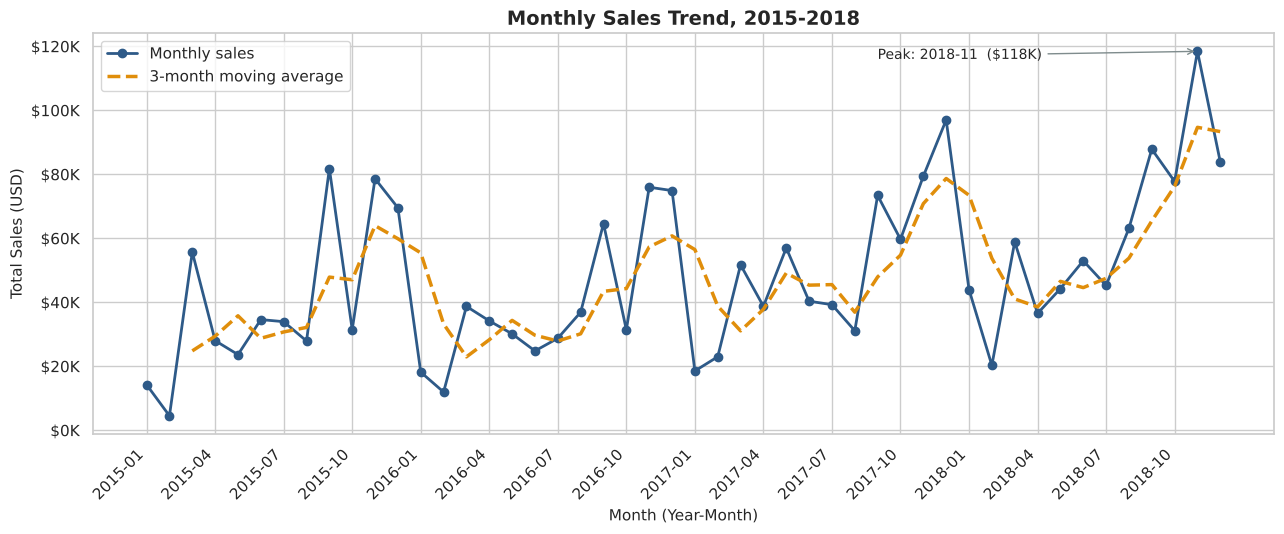

In [42]:
# Chart 1: Monthly Sales Trend (line chart)
monthly_plot = df.groupby("Year-Month")["Sales"].sum().reset_index()
monthly_plot["3-Month Moving Avg"] = monthly_plot["Sales"].rolling(3).mean()
x = np.arange(len(monthly_plot))

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(x, monthly_plot["Sales"], marker="o", lw=2, color=BLUE, label="Monthly sales")
ax.plot(x, monthly_plot["3-Month Moving Avg"], lw=2.5, ls="--", color=ORANGE, label="3-month moving average")

peak_i = monthly_plot["Sales"].idxmax()
ax.annotate(f"Peak: {monthly_plot.loc[peak_i, 'Year-Month']}  (${monthly_plot.loc[peak_i, 'Sales']/1000:,.0f}K)",
            xy=(peak_i, monthly_plot.loc[peak_i, "Sales"]), xytext=(peak_i - 14, monthly_plot.loc[peak_i, "Sales"] * 0.98),
            arrowprops=dict(arrowstyle="->", color=GREY), fontsize=10)

ax.set_xticks(x[::3])
ax.set_xticklabels(monthly_plot["Year-Month"].iloc[::3], rotation=45, ha="right")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money_k))
ax.set_title("Monthly Sales Trend, 2015-2018")
ax.set_xlabel("Month (Year-Month)")
ax.set_ylabel("Total Sales (USD)")
ax.legend(loc="upper left")
save_fig("01_monthly_sales_trend.png")

**Interpretation:** sales show a clear upward trend with a **sharp year-end spike every year** (September to December). Growth accelerates from 2017, and the highest month is **November 2018 (about \$118K)**. The moving average smooths the spikes and confirms the long-run climb, so the business can plan around a predictable annual peak.

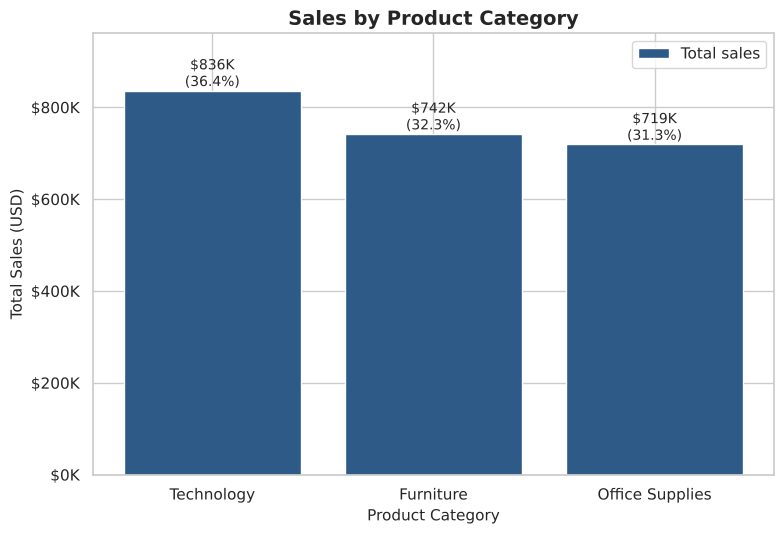

In [43]:
# Chart 2: Category-wise Sales (bar chart)
cat_plot = df.groupby("Category")["Sales"].sum().sort_values(ascending=False).reset_index()
cat_plot["Share"] = cat_plot["Sales"] / cat_plot["Sales"].sum() * 100

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(cat_plot["Category"], cat_plot["Sales"], color=BLUE, label="Total sales")
for bar, share in zip(bars, cat_plot["Share"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"${bar.get_height()/1000:,.0f}K\n({share:.1f}%)", ha="center", va="bottom", fontsize=10)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money_k))
ax.set_ylim(0, cat_plot["Sales"].max() * 1.15)
ax.set_title("Sales by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Total Sales (USD)")
ax.legend()
save_fig("02_sales_by_category.png")

**Interpretation:** the three categories are close in size, with **Technology (about 36%)** slightly ahead of Furniture (32%) and Office Supplies (31%). Sales alone suggests an even business, but the next profit chart shows the categories are very different in quality.

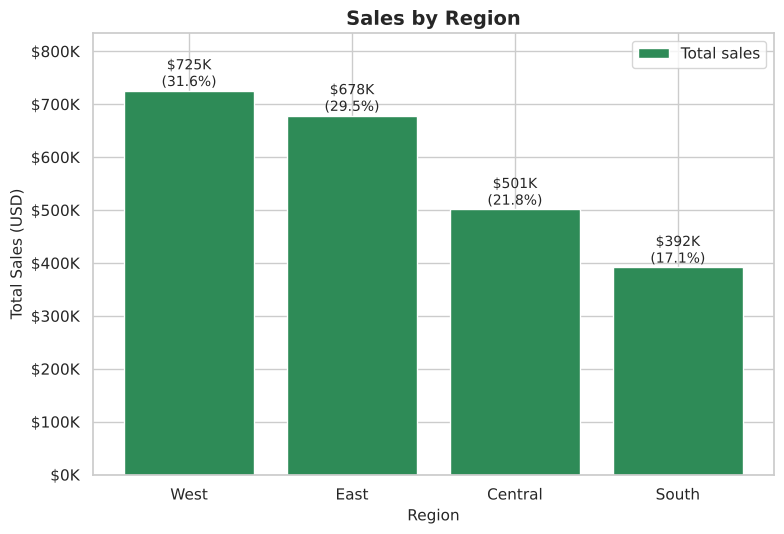

In [44]:
# Chart 3: Region-wise Sales (bar chart)
reg_plot = df.groupby("Region")["Sales"].sum().sort_values(ascending=False).reset_index()
reg_plot["Share"] = reg_plot["Sales"] / reg_plot["Sales"].sum() * 100

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(reg_plot["Region"], reg_plot["Sales"], color=GREEN, label="Total sales")
for bar, share in zip(bars, reg_plot["Share"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"${bar.get_height()/1000:,.0f}K\n({share:.1f}%)", ha="center", va="bottom", fontsize=10)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money_k))
ax.set_ylim(0, reg_plot["Sales"].max() * 1.15)
ax.set_title("Sales by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Total Sales (USD)")
ax.legend()
save_fig("03_sales_by_region.png")

**Interpretation:** **West (about 32%)** and **East (about 30%)** together bring in over 60% of sales. **South is the smallest region (about 17%)**, so it has the most room to grow. Sales volume alone does not show profitability, which is checked in the discount and insight sections.

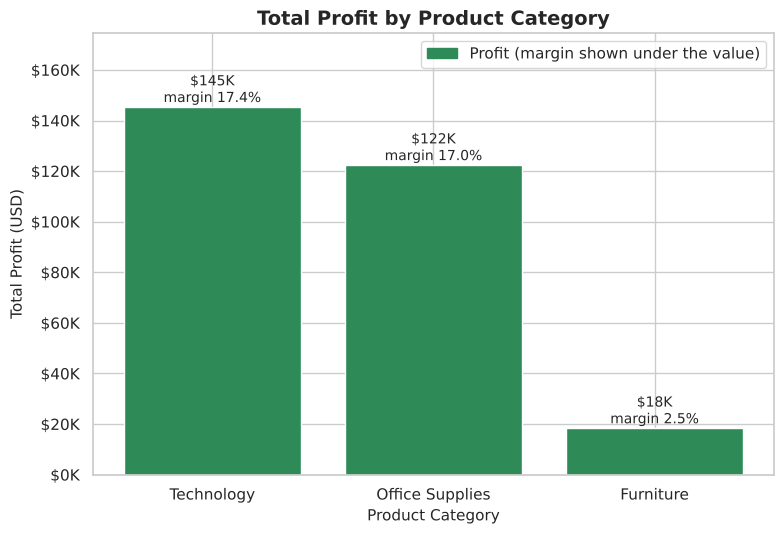

In [45]:
# Chart 4: Profit by Category (bar chart)
prof_plot = df.groupby("Category").agg(Profit=("Profit", "sum"), Sales=("Sales", "sum")).reset_index()
prof_plot["Margin"] = prof_plot["Profit"] / prof_plot["Sales"] * 100
prof_plot = prof_plot.sort_values("Profit", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
colors = [GREEN if p >= 0 else RED for p in prof_plot["Profit"]]
bars = ax.bar(prof_plot["Category"], prof_plot["Profit"], color=colors)
for bar, margin in zip(bars, prof_plot["Margin"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"${bar.get_height()/1000:,.0f}K\nmargin {margin:.1f}%", ha="center", va="bottom", fontsize=10)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money_k))
ax.set_ylim(0, prof_plot["Profit"].max() * 1.2)
ax.set_title("Total Profit by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Total Profit (USD)")
ax.legend(handles=[Patch(color=GREEN, label="Profit (margin shown under the value)")], loc="upper right")
save_fig("04_profit_by_category.png")

**Interpretation:** this is the most important contrast in the data. **Technology (\$145K) and Office Supplies (\$122K) earn about 17% margins, but Furniture earns only \$18K (2.5% margin)** on nearly the same sales as the other two. Furniture is about a third of sales but only about 6% of profit.

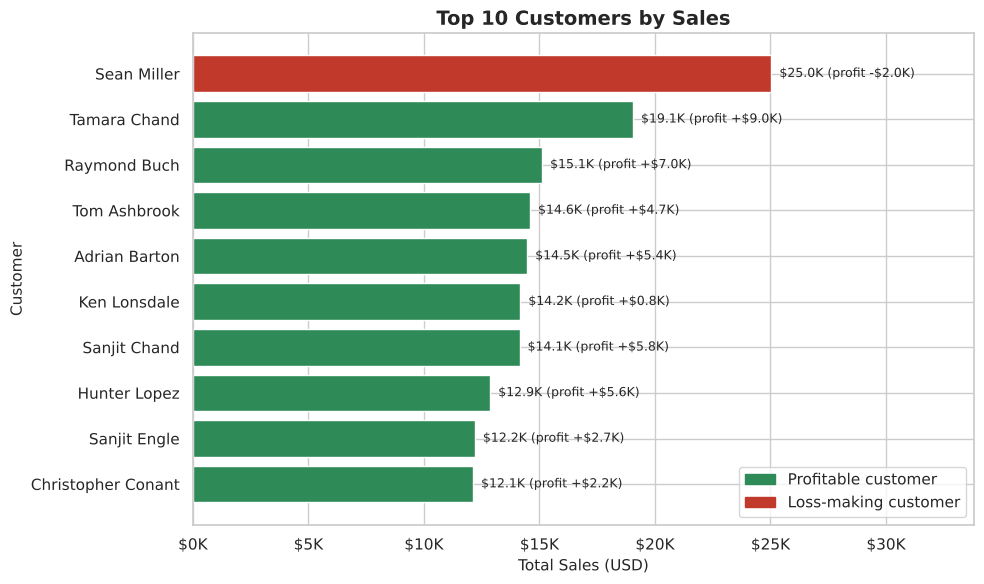

In [46]:
# Chart 5: Top 10 Customers by sales (horizontal bar chart)
top10 = customer_summary.head(10).iloc[::-1]          # reversed so the biggest is on top
bar_colors = [GREEN if p >= 0 else RED for p in top10["Profit"]]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top10["Customer Name"], top10["Sales"], color=bar_colors)
for bar, (sales_v, profit_v) in zip(bars, zip(top10["Sales"], top10["Profit"])):
    sign = "+" if profit_v >= 0 else "-"
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f"  \\${sales_v/1000:,.1f}K (profit {sign}\\${abs(profit_v)/1000:,.1f}K)", va="center", fontsize=9)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(money_k))
ax.set_xlim(0, top10["Sales"].max() * 1.35)
ax.set_title("Top 10 Customers by Sales")
ax.set_xlabel("Total Sales (USD)")
ax.set_ylabel("Customer")
ax.legend(handles=[Patch(color=GREEN, label="Profitable customer"), Patch(color=RED, label="Loss-making customer")],
          loc="lower right")
save_fig("05_top10_customers.png")

**Interpretation:** the biggest customer, **Sean Miller (about \$25K in sales), has a negative total profit**, so he is shown in red. The other nine top customers are profitable. Ranking customers by sales alone can therefore reward accounts that cost money; profit should sit next to sales in customer reports.

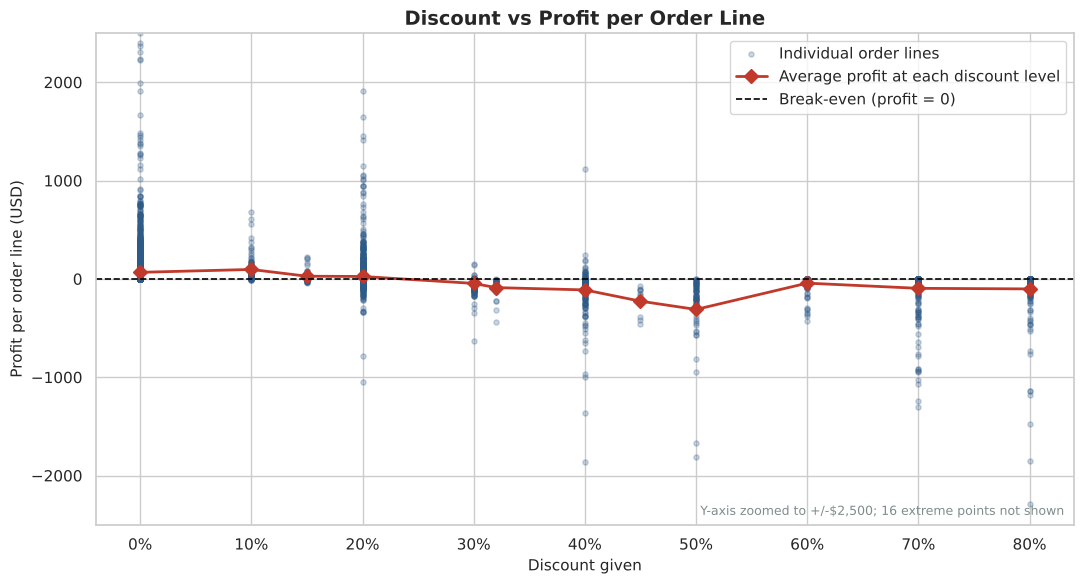

In [47]:
# Chart 6: Discount vs Profit (scatter plot)
mean_by_discount = df.groupby("Discount")["Profit"].mean()
y_limit = 2500
n_outside = int((df["Profit"].abs() > y_limit).sum())

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(df["Discount"], df["Profit"], s=14, alpha=0.25, color=BLUE, label="Individual order lines")
ax.plot(mean_by_discount.index, mean_by_discount.values, color=RED, marker="D", lw=2, markersize=7,
        label="Average profit at each discount level")
ax.axhline(0, color="black", lw=1.2, ls="--", label="Break-even (profit = 0)")
ax.set_ylim(-y_limit, y_limit)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Discount vs Profit per Order Line")
ax.set_xlabel("Discount given")
ax.set_ylabel("Profit per order line (USD)")
ax.text(0.99, 0.02, f"Y-axis zoomed to +/-${y_limit:,}; {n_outside} extreme points not shown",
        transform=ax.transAxes, ha="right", fontsize=9, color=GREY)
ax.legend(loc="upper right")
save_fig("06_discount_vs_profit_scatter.png")

**Interpretation:** at 0% discount, profits are spread widely and mostly positive. As the discount rises, the **average profit (red line) falls and drops below break-even at about 30%**; beyond 40-50% **nearly every point is a loss**. This shows association only; product mix and region also differ between discount levels.

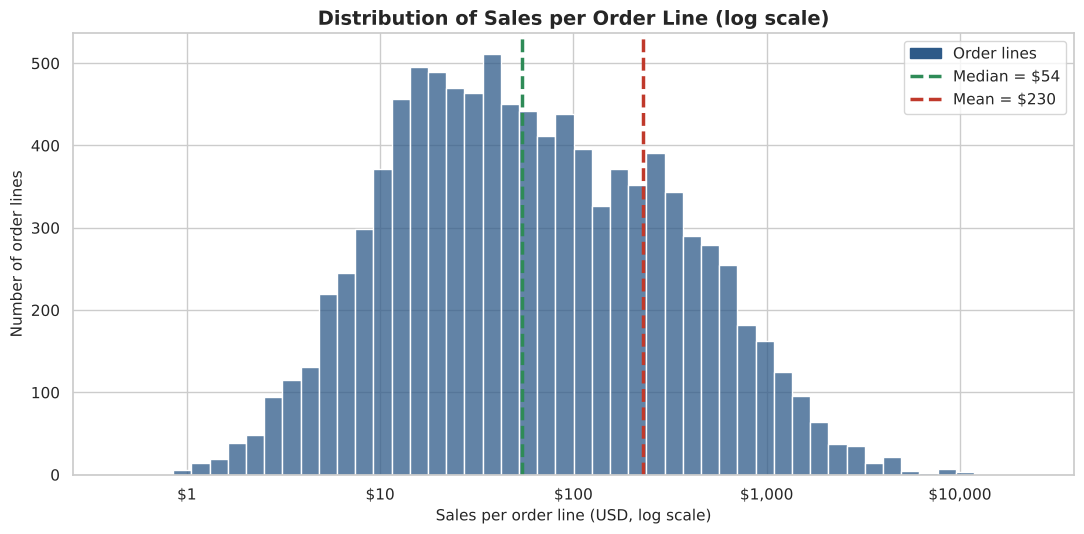

In [48]:
# Chart 7: Sales Distribution (histogram, log scale because sales are very skewed)
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.histplot(df["Sales"], bins=50, log_scale=True, color=BLUE, ax=ax)
median_v, mean_v = df["Sales"].median(), df["Sales"].mean()
ax.axvline(median_v, color=GREEN, lw=2.5, ls="--")
ax.axvline(mean_v, color=RED, lw=2.5, ls="--")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"${v:,.0f}"))
ax.set_title("Distribution of Sales per Order Line (log scale)")
ax.set_xlabel("Sales per order line (USD, log scale)")
ax.set_ylabel("Number of order lines")
ax.legend(handles=[Patch(color=BLUE, label="Order lines"),
                   Line2D([0], [0], color=GREEN, lw=2.5, ls="--", label=f"Median = ${median_v:,.0f}"),
                   Line2D([0], [0], color=RED, lw=2.5, ls="--", label=f"Mean = ${mean_v:,.0f}")],
          loc="upper right")
save_fig("07_sales_distribution_histogram.png")

**Interpretation:** most order lines are small. The **median is about \$54 while the mean is about \$230**, because a long tail of big-ticket items pulls the average up. Business reporting should therefore use the median (or segments) for a "typical" sale, and treat the big-ticket lines as a separate group.

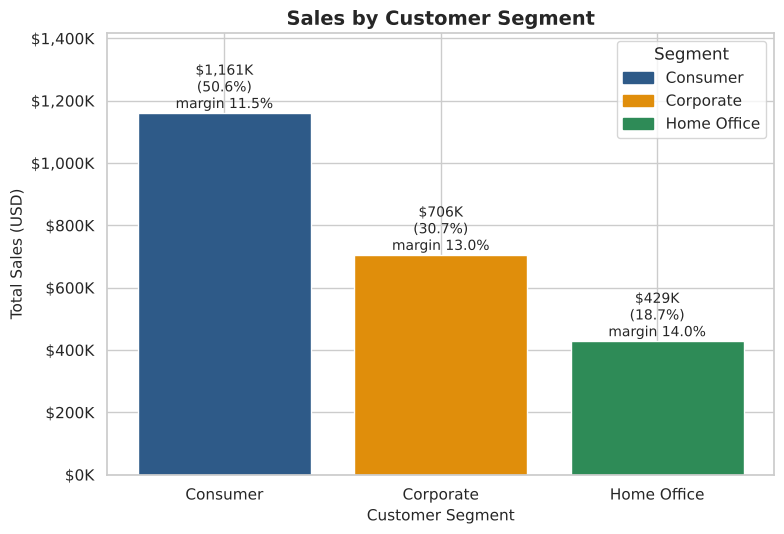

In [49]:
# Chart 8: Sales by Segment (bar chart with share labels)
seg_plot = df.groupby("Segment").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).sort_values("Sales", ascending=False).reset_index()
seg_plot["Share"] = seg_plot["Sales"] / seg_plot["Sales"].sum() * 100
seg_plot["Margin"] = seg_plot["Profit"] / seg_plot["Sales"] * 100

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(seg_plot["Segment"], seg_plot["Sales"], color=[BLUE, ORANGE, GREEN], label="Total sales")
for bar, share, margin in zip(bars, seg_plot["Share"], seg_plot["Margin"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"${bar.get_height()/1000:,.0f}K\n({share:.1f}%)\nmargin {margin:.1f}%", ha="center", va="bottom", fontsize=10)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money_k))
ax.set_ylim(0, seg_plot["Sales"].max() * 1.22)
ax.set_title("Sales by Customer Segment")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Total Sales (USD)")
ax.legend(handles=[Patch(color=c, label=s) for c, s in zip([BLUE, ORANGE, GREEN], seg_plot["Segment"])], title="Segment")
save_fig("08_sales_by_segment.png")

**Interpretation:** **Consumer is about half of all sales (51%)**, Corporate about 31% and Home Office about 19%. The smaller segments are actually **more profitable per dollar** (Home Office about 14% margin, Corporate 13%, Consumer 11.5%), so growing Corporate and Home Office accounts could lift overall margin.

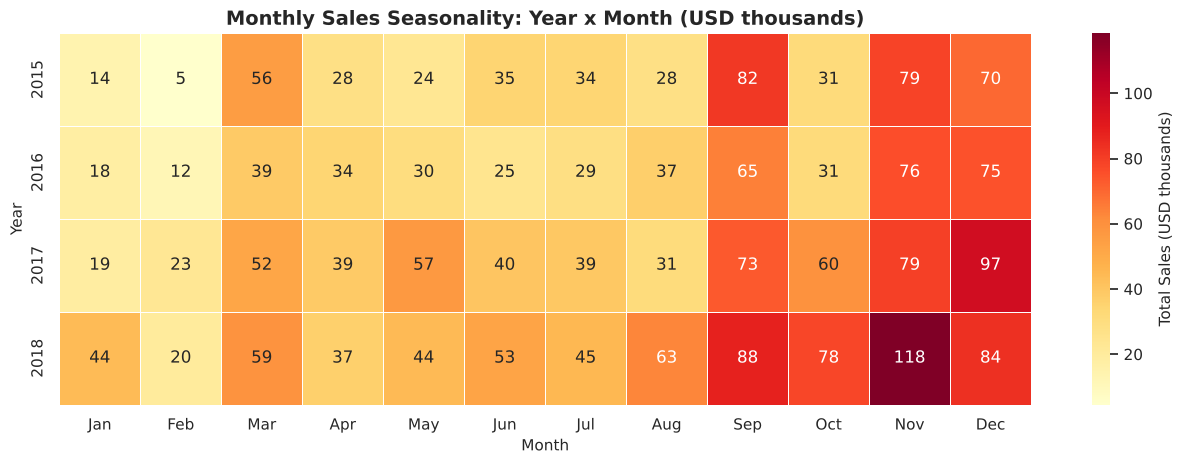

In [50]:
# Chart 9: Monthly Sales Seasonality (heatmap: Year x Month)
heat = season_pivot.copy()
heat.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(13, 4.8))
sns.heatmap(heat / 1000, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.6, ax=ax,
            cbar_kws={"label": "Total Sales (USD thousands)"})
ax.set_title("Monthly Sales Seasonality: Year x Month (USD thousands)")
ax.set_xlabel("Month")
ax.set_ylabel("Year")
save_fig("09_monthly_seasonality_heatmap.png")

**Interpretation:** the dark columns for **September, November and December repeat in every year**, while **January and February stay pale**. The darkest single cell is November 2018 (about \$118K) and the palest is February 2015 (about \$5K). The seasonal shape is stable, so it can be planned for.

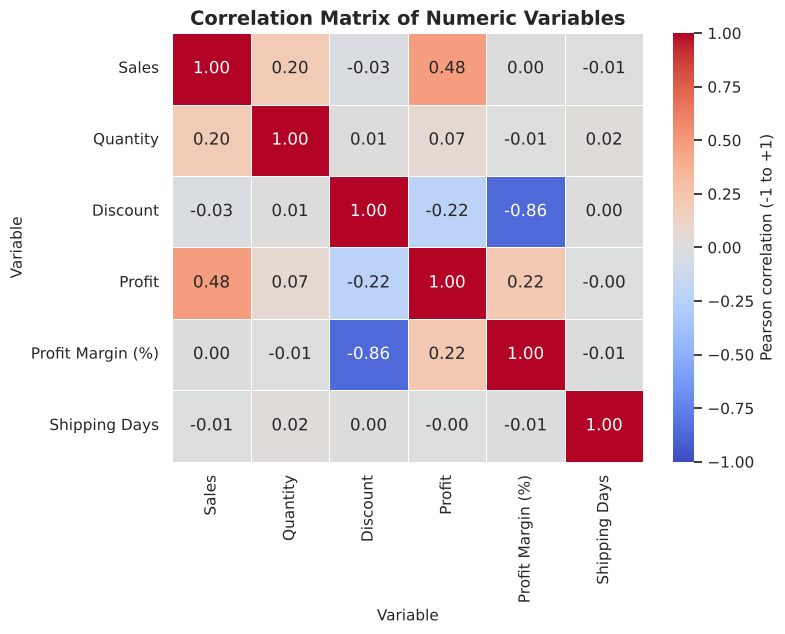

,Sales,Quantity,Discount,Profit,Profit Margin (%),Shipping Days
Sales,1.00,0.20,-0.03,0.48,0.00,-0.01
Quantity,0.20,1.00,0.01,0.07,-0.01,0.02
Discount,-0.03,0.01,1.00,-0.22,-0.86,0.00
Profit,0.48,0.07,-0.22,1.00,0.22,-0.00
Profit Margin (%),0.00,-0.01,-0.86,0.22,1.00,-0.01
Shipping Days,-0.01,0.02,0.00,-0.00,-0.01,1.00


In [51]:
# Chart 10: Correlation Matrix (heatmap)
corr_cols = [c for c in ["Sales", "Quantity", "Discount", "Profit", "Profit Margin (%)", "Shipping Days"] if c in df.columns]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, linewidths=0.6, ax=ax,
            cbar_kws={"label": "Pearson correlation (-1 to +1)"})
ax.set_title("Correlation Matrix of Numeric Variables")
ax.set_xlabel("Variable")
ax.set_ylabel("Variable")
save_fig("10_correlation_matrix.png")
display(corr)

**Interpretation:** **Sales and Profit move together (positive, about 0.48)**, as expected. **Discount has a negative relationship with both Profit and Profit Margin**, and it is much more strongly tied to *margin* (about -0.86) than to profit in dollars (about -0.22), because a discount cuts the percentage earned on every sale. Discount has almost no link with Sales or Quantity, so deeper discounts here do **not** come with bigger orders. Shipping days is unrelated to the other variables. Correlation does not prove cause.

### Extra charts (support the insights)

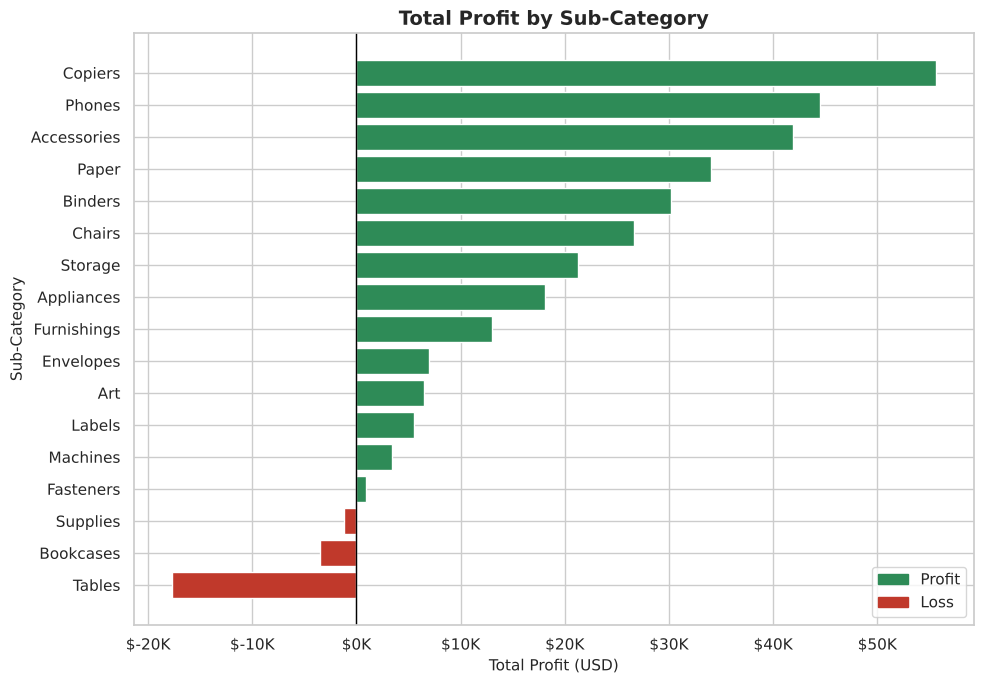

In [52]:
# Extra chart 11: Profit by Sub-Category
sub_plot = subcat_summary.sort_values("Profit")

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(sub_plot["Sub-Category"], sub_plot["Profit"], color=[GREEN if p >= 0 else RED for p in sub_plot["Profit"]])
ax.axvline(0, color="black", lw=1)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(money_k))
ax.set_title("Total Profit by Sub-Category")
ax.set_xlabel("Total Profit (USD)")
ax.set_ylabel("Sub-Category")
ax.legend(handles=[Patch(color=GREEN, label="Profit"), Patch(color=RED, label="Loss")], loc="lower right")
save_fig("11_profit_by_subcategory.png")

**Interpretation:** **Tables (about -\$17.7K), Bookcases (-\$3.5K) and Supplies (-\$1.2K) lose money.** The best earners are Copiers, Phones, Accessories, Paper and Binders. The Furniture problem is concentrated in two sub-categories rather than the whole category.

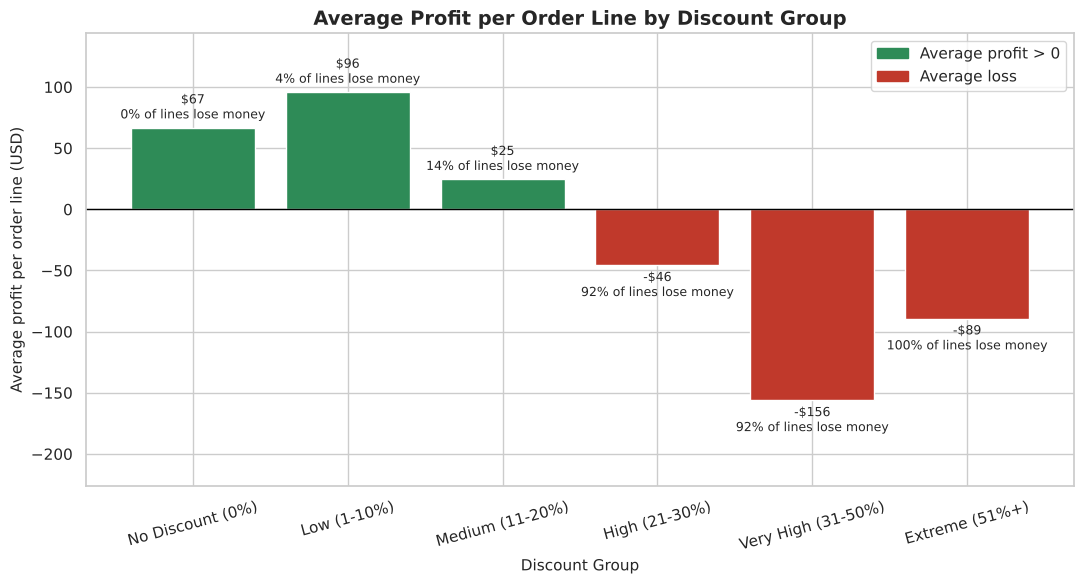

In [53]:
# Extra chart 12: Average profit per line and share of loss-making lines by Discount Group
disc_plot = discount_summary.reset_index()

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(disc_plot["Discount Group"].astype(str), disc_plot["Avg_Profit"],
              color=[GREEN if v >= 0 else RED for v in disc_plot["Avg_Profit"]])
for bar, loss_share in zip(bars, disc_plot["Loss-Making Lines (%)"]):
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, y + (4 if y >= 0 else -4),
            f"{'-' if y < 0 else ''}${abs(y):,.0f}\n{loss_share:.0f}% of lines lose money", ha="center", va="bottom" if y >= 0 else "top", fontsize=9)
ax.axhline(0, color="black", lw=1)
ax.set_ylim(disc_plot["Avg_Profit"].min() * 1.45, disc_plot["Avg_Profit"].max() * 1.5)
ax.set_title("Average Profit per Order Line by Discount Group")
ax.set_xlabel("Discount Group")
ax.set_ylabel("Average profit per order line (USD)")
ax.legend(handles=[Patch(color=GREEN, label="Average profit > 0"), Patch(color=RED, label="Average loss")], loc="upper right")
plt.xticks(rotation=15)
save_fig("12_avg_profit_by_discount_group.png")

**Interpretation:** average profit per line drops from roughly **\$67 at no discount** to a **loss in every group above 20%**. In the 21-30%, 31-50% and 51%+ groups, 92%, 92% and 100% of lines lose money respectively. The 11-20% band is the last one that still earns a healthy profit.

## 15. Key Business Insights

Each insight has **Observation, Evidence, Business meaning and Recommended action**. The code below calculates every number from the clean dataset and writes the text, so nothing is hard-coded.

In [54]:
# ---------- Calculate the numbers used in the insights ----------
# 1) Discounts
n_hi = len(above20)
share_hi = n_hi / len(df) * 100
profit_hi = above20["Profit"].sum()
loss_share_hi = (above20["Profit"] < 0).mean() * 100
margin_none = discount_summary.loc["No Discount (0%)", "Profit Margin (%)"]
mid_lines = df[(df["Discount"] > 0) & (df["Discount"] <= 0.20)]
margin_mid = mid_lines["Profit"].sum() / mid_lines["Sales"].sum() * 100

# 2) Furniture
fur = category_summary.loc["Furniture"]
tech = category_summary.loc["Technology"]
office = category_summary.loc["Office Supplies"]
sub = subcat_summary.set_index("Sub-Category")
tables_hi = tables.loc[tables["Discount"] > 0.20, "Profit"].sum()
tables_lo = tables.loc[tables["Discount"] <= 0.20, "Profit"].sum()

# 3) Seasonality
season = seasonality.set_index("Month Name")
months_q4 = q4_months_share
nov_share = season.loc["Nov", "Share of Sales (%)"]
feb_share = season.loc["Feb", "Share of Sales (%)"]
years_with_pattern = sum(set(row.nlargest(3).index) == {9, 11, 12} for _, row in season_pivot.iterrows())

# 4) Central region
reg = region_summary
central_hi_share = (df.loc[df["Region"] == "Central", "Discount"] > 0.20).mean() * 100
west_hi_share = (df.loc[df["Region"] == "West", "Discount"] > 0.20).mean() * 100
texas = state_summary.set_index("State").loc["Texas"]
central_states = state_summary[(state_summary["Region"] == "Central") & (state_summary["Sales"] >= 50000)]
c_best = central_states.loc[central_states["Profit Margin (%)"].idxmax()]
c_worst = central_states.loc[central_states["Profit Margin (%)"].idxmin()]

# 5) Growth vs profit
g17, g18 = yearly.loc[2017, "Sales Growth (%)"], yearly.loc[2018, "Sales Growth (%)"]
pg18 = yearly.loc[2018, "Profit Growth (%)"]
m17, m18 = yearly.loc[2017, "Profit Margin (%)"], yearly.loc[2018, "Profit Margin (%)"]

# 6) Customers
top_cust = customer_summary.iloc[0]

# 7) Returns
ret_df = df[df["Is Returned"]]
n_ret_orders = ret_df["Order ID"].nunique()
ret_order_share = n_ret_orders / total_orders * 100
ret_sales = ret_df["Sales"].sum()
ret_sales_share = ret_sales / total_sales * 100
aov_ret = order_totals.loc[order_totals.index.isin(returned_orders), "Order_Sales"].mean()
aov_not = order_totals.loc[~order_totals.index.isin(returned_orders), "Order_Sales"].mean()
ret_by_cat = ret_df.groupby("Category")["Sales"].sum() / df.groupby("Category")["Sales"].sum() * 100
ret_top_cat = ret_by_cat.idxmax()

# ---------- Write the insights ----------
insights = [
    {
        "title": "Discounts above 20% are almost always loss-making",
        "observation": "Order lines discounted by more than 20% rarely make money, while undiscounted lines are very profitable.",
        "evidence": (f"{n_hi:,} lines ({share_hi:.1f}% of all lines) are discounted above 20%. Together they lost {fm(-profit_hi)}, "
                     f"and {loss_share_hi:.0f}% of them individually lost money. Lines with no discount earn a {margin_none:.1f}% margin "
                     f"versus {margin_mid:.1f}% for 1-20% discounts. The Spearman correlation between discount and profit is {spearman:.2f}."),
        "meaning": ("Deep discounts and profit move in opposite directions, and every discount band above 20% has a negative total profit. "
                    "This is an association, not proof of cause, because discounted lines also differ in product mix and region."),
        "action": ("Set a 20% standard discount ceiling, require manager approval above it, and track margin after discount every month. "
                   "Pilot the rule in one region first to measure the real effect."),
    },
    {
        "title": "Furniture sells a lot but earns very little",
        "observation": "Furniture is about a third of sales, but contributes only a small part of profit.",
        "evidence": (f"Furniture is {fur['Sales Share (%)']:.1f}% of sales but only {fur['Profit Share (%)']:.1f}% of profit "
                     f"(margin {fur['Profit Margin (%)']:.1f}% vs {tech['Profit Margin (%)']:.1f}% for Technology and "
                     f"{office['Profit Margin (%)']:.1f}% for Office Supplies). Tables lost {fm(-sub.loc['Tables', 'Profit'])} "
                     f"({sub.loc['Tables', 'Profit Margin (%)']:.1f}% margin) and Bookcases lost {fm(-sub.loc['Bookcases', 'Profit'])}. "
                     f"Table lines discounted above 20% lost {fm(-tables_hi)}, while Table lines at 20% or less made {fm(tables_lo)}."),
        "meaning": ("The category's weak profit is concentrated in two sub-categories, and heavy discounting appears to be a major part of the "
                    "Tables problem. Chairs and Furnishings remain profitable."),
        "action": ("Review prices and supplier costs for Tables and Bookcases, stop deep discounts on them, "
                   "and move promotional budget toward Technology and Office Supplies."),
    },
    {
        "title": "Sales are concentrated in September to December",
        "observation": "Demand is strongly seasonal, with a repeating year-end peak and a weak start to the year.",
        "evidence": (f"September to December generate {months_q4:.1f}% of sales (November alone {nov_share:.1f}%). February is the weakest month "
                     f"({feb_share:.1f}% of sales). September, November and December were the three biggest months in {years_with_pattern} of "
                     f"{n_years} years."),
        "meaning": ("The pattern is stable, so inventory, staffing and marketing can be planned in advance. The likely cause is year-end buying, "
                    "although the data cannot confirm the reason."),
        "action": ("Build stock and shipping capacity before September. In January-February use bundles and value offers rather than deep discounts to lift "
                   "the slow months."),
    },
    {
        "title": "The Central region has the weakest margin",
        "observation": "West is the best region on sales and profit; Central earns far less per dollar of sales.",
        "evidence": (f"Central has {fm(reg.loc['Central', 'Sales'])} in sales ({reg.loc['Central', 'Sales Share (%)']:.1f}%) but a "
                     f"{reg.loc['Central', 'Profit Margin (%)']:.1f}% margin versus {reg.loc['West', 'Profit Margin (%)']:.1f}% in West. "
                     f"Its average discount is {reg.loc['Central', 'Avg_Discount']:.1f}% versus {reg.loc['West', 'Avg_Discount']:.1f}% in West, and "
                     f"{central_hi_share:.1f}% of Central lines are discounted above 20% (West: {west_hi_share:.1f}%). "
                     f"Texas lost {fm(-texas['Profit'])} with an average discount of {texas['Avg_Discount']:.1f}%. Inside Central, "
                     f"{c_best['State']} (average discount {c_best['Avg_Discount']:.1f}%) earned a {c_best['Profit Margin (%)']:.1f}% margin, "
                     f"while {c_worst['State']} (average discount {c_worst['Avg_Discount']:.1f}%) ran at {c_worst['Profit Margin (%)']:.1f}%."),
        "meaning": ("Central's lower margin coincides with much heavier discounting. Product mix and local costs may also contribute, "
                    "so a drill-down is needed before drawing a final conclusion."),
        "action": ("Audit discount approvals in Central, starting with Texas. Compare Central and West discounting product by product, "
                   "and set a minimum margin target for each region."),
    },
    {
        "title": "Sales growth is strong, but margin slipped in 2018",
        "observation": "Revenue is growing faster than profit.",
        "evidence": (f"Sales grew {g17:.1f}% in 2017 and {g18:.1f}% in 2018 (to {fm(yearly.loc[2018, 'Sales'])}), but 2018 profit grew only "
                     f"{pg18:.1f}% and the margin fell from {m17:.1f}% to {m18:.1f}%."),
        "meaning": "Each extra dollar of sales is now worth slightly less profit, so growth is becoming a little less efficient.",
        "action": "Make profit margin a headline KPI next to sales, and link sales targets to margin, not revenue alone.",
    },
    {
        "title": "The customer base is broad, and the biggest customer by sales lost money",
        "observation": "Revenue is not dependent on a few accounts, but sales rank hides unprofitable customers.",
        "evidence": (f"There are {n_customers:,} customers. The top 10 contribute only {top10_share:.1f}% of sales and the top 20% contribute "
                     f"{top20pct_share:.1f}%. The #1 customer by sales ({top_cust['Customer Name']}) generated {fm(top_cust['Sales'])} in sales but "
                     f"{fm(top_cust['Profit'])} in profit. {len(loss_customers)} customers ({len(loss_customers) / n_customers * 100:.1f}%) have negative "
                     f"total profit, adding up to {fm(loss_customers['Profit'].sum())}."),
        "meaning": "Concentration risk is low, but ranking customers by sales alone can reward accounts that cost money.",
        "action": ("Show profit next to sales in customer reports, review the discounts given to loss-making accounts, "
                   "and use loyalty offers to grow the broad middle tier."),
    },
    {
        "title": "Returned orders take a noticeable share of sales",
        "observation": "A measurable part of orders is returned, and returned orders are different in size.",
        "evidence": (f"{n_ret_orders} orders ({ret_order_share:.1f}% of all orders) appear in the appended Returns table, worth {fm(ret_sales)} "
                     f"({ret_sales_share:.1f}% of sales). Their average order value is {fm(aov_ret)} versus {fm(aov_not)} for other orders. "
                     f"{ret_top_cat} has the highest share of its sales returned ({ret_by_cat.max():.1f}%)."),
        "meaning": ("Returned orders are worth more than a typical order, so each return costs more than the order count suggests. "
                    "Return reasons and refund amounts are not in the data, so the exact profit impact cannot be measured here."),
        "action": f"Start recording return reasons and refund values, and investigate {ret_top_cat} returns first.",
    },
]

for i, ins in enumerate(insights, start=1):
    text = (f"### Insight {i}: {ins['title']}\n\n"
            f"* **Observation:** {ins['observation']}\n"
            f"* **Evidence:** {ins['evidence']}\n"
            f"* **Business meaning:** {ins['meaning']}\n"
            f"* **Recommended action:** {ins['action']}\n")
    display(Markdown(md_safe(text)))

### Insight 1: Discounts above 20% are almost always loss-making

* **Observation:** Order lines discounted by more than 20% rarely make money, while undiscounted lines are very profitable.
* **Evidence:** 1,392 lines (13.9% of all lines) are discounted above 20%. Together they lost \$135.4K, and 97% of them individually lost money. Lines with no discount earn a 29.5% margin versus 11.9% for 1-20% discounts. The Spearman correlation between discount and profit is -0.54.
* **Business meaning:** Deep discounts and profit move in opposite directions, and every discount band above 20% has a negative total profit. This is an association, not proof of cause, because discounted lines also differ in product mix and region.
* **Recommended action:** Set a 20% standard discount ceiling, require manager approval above it, and track margin after discount every month. Pilot the rule in one region first to measure the real effect.


### Insight 2: Furniture sells a lot but earns very little

* **Observation:** Furniture is about a third of sales, but contributes only a small part of profit.
* **Evidence:** Furniture is 32.3% of sales but only 6.4% of profit (margin 2.5% vs 17.4% for Technology and 17.0% for Office Supplies). Tables lost \$17.7K (-8.6% margin) and Bookcases lost \$3.5K. Table lines discounted above 20% lost \$30.7K, while Table lines at 20% or less made \$13.0K.
* **Business meaning:** The category's weak profit is concentrated in two sub-categories, and heavy discounting appears to be a major part of the Tables problem. Chairs and Furnishings remain profitable.
* **Recommended action:** Review prices and supplier costs for Tables and Bookcases, stop deep discounts on them, and move promotional budget toward Technology and Office Supplies.


### Insight 3: Sales are concentrated in September to December

* **Observation:** Demand is strongly seasonal, with a repeating year-end peak and a weak start to the year.
* **Evidence:** September to December generate 51.6% of sales (November alone 15.3%). February is the weakest month (2.6% of sales). September, November and December were the three biggest months in 4 of 4 years.
* **Business meaning:** The pattern is stable, so inventory, staffing and marketing can be planned in advance. The likely cause is year-end buying, although the data cannot confirm the reason.
* **Recommended action:** Build stock and shipping capacity before September. In January-February use bundles and value offers rather than deep discounts to lift the slow months.


### Insight 4: The Central region has the weakest margin

* **Observation:** West is the best region on sales and profit; Central earns far less per dollar of sales.
* **Evidence:** Central has \$501.2K in sales (21.8%) but a 7.9% margin versus 14.9% in West. Its average discount is 24.0% versus 10.9% in West, and 27.7% of Central lines are discounted above 20% (West: 3.7%). Texas lost \$25.7K with an average discount of 37.0%. Inside Central, Indiana (average discount 0.0%) earned a 34.3% margin, while Illinois (average discount 39.0%) ran at -15.7%.
* **Business meaning:** Central's lower margin coincides with much heavier discounting. Product mix and local costs may also contribute, so a drill-down is needed before drawing a final conclusion.
* **Recommended action:** Audit discount approvals in Central, starting with Texas. Compare Central and West discounting product by product, and set a minimum margin target for each region.


### Insight 5: Sales growth is strong, but margin slipped in 2018

* **Observation:** Revenue is growing faster than profit.
* **Evidence:** Sales grew 29.5% in 2017 and 20.4% in 2018 (to \$733.2K), but 2018 profit grew only 14.2% and the margin fell from 13.4% to 12.7%.
* **Business meaning:** Each extra dollar of sales is now worth slightly less profit, so growth is becoming a little less efficient.
* **Recommended action:** Make profit margin a headline KPI next to sales, and link sales targets to margin, not revenue alone.


### Insight 6: The customer base is broad, and the biggest customer by sales lost money

* **Observation:** Revenue is not dependent on a few accounts, but sales rank hides unprofitable customers.
* **Evidence:** There are 793 customers. The top 10 contribute only 6.7% of sales and the top 20% contribute 48.1%. The #1 customer by sales (Sean Miller) generated \$25.0K in sales but -\$2.0K in profit. 155 customers (19.5%) have negative total profit, adding up to -\$71.2K.
* **Business meaning:** Concentration risk is low, but ranking customers by sales alone can reward accounts that cost money.
* **Recommended action:** Show profit next to sales in customer reports, review the discounts given to loss-making accounts, and use loyalty offers to grow the broad middle tier.


### Insight 7: Returned orders take a noticeable share of sales

* **Observation:** A measurable part of orders is returned, and returned orders are different in size.
* **Evidence:** 296 orders (5.9% of all orders) appear in the appended Returns table, worth \$180.5K (7.9% of sales). Their average order value is \$610 versus \$449 for other orders. Technology has the highest share of its sales returned (8.7%).
* **Business meaning:** Returned orders are worth more than a typical order, so each return costs more than the order count suggests. Return reasons and refund amounts are not in the data, so the exact profit impact cannot be measured here.
* **Recommended action:** Start recording return reasons and refund values, and investigate Technology returns first.


## 16. Business Recommendations

Ordered by priority. Each one links back to the evidence above.

**Do now (policy changes, low cost)**
1. **Introduce discount guardrails.** Cap standard discounts at 20% and require approval above that. This targets the biggest and clearest profit leak (Insight 1).
2. **Audit the Central region**, starting with Texas, and compare its discounting with West (Insight 4).

**Do next (1-2 quarters)**
3. **Reprice or rework Tables and Bookcases**: check supplier costs, stop deep discounts, and shift promotion to Technology and Office Supplies (Insight 2).
4. **Plan the year around the seasonal peak**: stock and staff up before September, and use value bundles (not deep discounts) to lift January-February (Insight 3).

**Build into regular reporting**
5. **Report profit margin and customer profit, not only sales**: add margin to the monthly dashboard and profit to every customer ranking (Insights 5 and 6).
6. **Capture return reasons and refund values**, so that returns can be linked to cost (Insight 7).
7. **Fix the data export.** The CSV mixed three tables in one file (Sales, People, Returns). Export each table to its own file, so no analyst has to clean them apart.

## 17. Final Conclusion

In [55]:
conclusion = f"""
**Summary.** Between {df['Order Date'].min().year} and {df['Order Date'].max().year} the business sold {fm(total_sales)} across {total_orders:,} orders
to {n_customers:,} customers and made {fm(total_profit)} of profit (a {overall_margin:.1f}% margin). Sales are growing
({g18:.1f}% in 2018), the customer base is broad, and demand follows a stable year-end peak.

**The main weakness is not demand but discounting.** Lines discounted above 20% lost {fm(-profit_hi)} in total, and the weakest areas
(Furniture tables and bookcases, the Central region, Texas) are also where discounts are heaviest. Fixing discount discipline is the
fastest route to higher profit, without needing a single extra sale.

**Limitations to keep in mind.**
* Discount and profit are *associated*; this analysis cannot prove that discounts *cause* the losses (product mix and region also differ).
* The data has no cost, return-reason or refund columns, and covers only 2015-2018.
* 11 missing Postal Codes were filled with Burlington VT's ZIP (05401); this does not affect any metric.
* The returns flag comes from a table that was appended to the sales file; we assumed every listed Order ID is a returned order.

**Next steps.** Pilot a discount cap, drill into Central and Texas by product, and add returns reasons to the data.
"""
display(Markdown(md_safe(conclusion)))


**Summary.** Between 2015 and 2018 the business sold \$2.30M across 5,009 orders
to 793 customers and made \$286.4K of profit (a 12.5% margin). Sales are growing
(20.4% in 2018), the customer base is broad, and demand follows a stable year-end peak.

**The main weakness is not demand but discounting.** Lines discounted above 20% lost \$135.4K in total, and the weakest areas
(Furniture tables and bookcases, the Central region, Texas) are also where discounts are heaviest. Fixing discount discipline is the
fastest route to higher profit, without needing a single extra sale.

**Limitations to keep in mind.**
* Discount and profit are *associated*; this analysis cannot prove that discounts *cause* the losses (product mix and region also differ).
* The data has no cost, return-reason or refund columns, and covers only 2015-2018.
* 11 missing Postal Codes were filled with Burlington VT's ZIP (05401); this does not affect any metric.
* The returns flag comes from a table that was appended to the sales file; we assumed every listed Order ID is a returned order.

**Next steps.** Pilot a discount cap, drill into Central and Texas by product, and add returns reasons to the data.


## Appendix: Export the Deliverables

This final step writes the insights file and the executive-summary PDF so everything can be regenerated by re-running the notebook.

In [56]:
# ---- Business Insights and Recommendations (Markdown file) ----
recommendations_text = """## Recommendations (in priority order)

**Do now (policy changes, low cost)**
1. **Introduce discount guardrails.** Cap standard discounts at 20% and require approval above that (Insight 1).
2. **Audit the Central region**, starting with Texas, and compare its discounting with West (Insight 4).

**Do next (1-2 quarters)**
3. **Reprice or rework Tables and Bookcases**: check supplier costs, stop deep discounts, shift promotion to Technology and Office Supplies (Insight 2).
4. **Plan around the seasonal peak**: stock and staff up before September; use value bundles, not deep discounts, to lift January-February (Insight 3).

**Build into regular reporting**
5. **Report profit margin and customer profit, not only sales** (Insights 5 and 6).
6. **Capture return reasons and refund values** so returns can be linked to cost (Insight 7).
7. **Fix the data export.** Export Sales, People and Returns as separate files.
"""

lines = ["# Business Insights and Recommendations", "",
         "*Superstore Retail Sales EDA. All figures are calculated from the uploaded dataset (cleaned: "
         f"{len(df):,} order lines, {df['Order Date'].min().date()} to {df['Order Date'].max().date()}).*", "",
         "## Key insights", ""]
for i, ins in enumerate(insights, start=1):
    lines += [f"### {i}. {ins['title']}", "",
              f"- **Observation:** {ins['observation']}",
              f"- **Evidence:** {ins['evidence']}",
              f"- **Business meaning:** {ins['meaning']}",
              f"- **Recommended action:** {ins['action']}", ""]
lines += [recommendations_text, "", "## Limitations",
          "- Discount and profit are associated; causation is not proven (product mix and region also differ).",
          "- No cost, return-reason or refund data; period covers 2015-2018 only.",
          "- 11 missing Postal Codes (Burlington, VT) were filled with 05401; no metric uses Postal Code.",
          "- Returns were taken from a table appended to the sales file; every listed Order ID was treated as returned."]
insights_path = os.path.join(OUTPUT_DIR, "Business_Insights_and_Recommendations.md")
with open(insights_path, "w", encoding="utf-8") as f:
    f.write(md_safe("\n".join(lines)))
print("Saved:", insights_path)

Saved: outputs/Business_Insights_and_Recommendations.md


In [57]:
# ---- Executive Summary (PDF) ----
try:
    from reportlab.lib.pagesizes import A4
    from reportlab.lib import colors
    from reportlab.lib.units import cm
    from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
    from reportlab.lib.utils import ImageReader
    from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image
    REPORTLAB_OK = True
except ImportError:
    REPORTLAB_OK = False
    print("reportlab is not installed. Run: pip install reportlab   (the PDF was skipped)")

if REPORTLAB_OK:
    def esc(text):
        """Make text safe for reportlab's mini-HTML."""
        return text.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")

    styles = getSampleStyleSheet()
    NAVY = colors.HexColor("#1F3A5F")
    title_style = ParagraphStyle("T", parent=styles["Title"], fontSize=20, textColor=NAVY, spaceAfter=2, alignment=0)
    sub_style = ParagraphStyle("S", parent=styles["Normal"], fontSize=9.5, textColor=colors.HexColor("#555555"), spaceAfter=8)
    h_style = ParagraphStyle("H", parent=styles["Heading2"], fontSize=12.5, textColor=NAVY, spaceBefore=8, spaceAfter=4)
    body = ParagraphStyle("B", parent=styles["Normal"], fontSize=9, leading=12)
    ins_title = ParagraphStyle("IT", parent=styles["Normal"], fontSize=10, leading=12, textColor=NAVY,
                               fontName="Helvetica-Bold", spaceBefore=5, spaceAfter=1)
    small = ParagraphStyle("SM", parent=body, fontSize=8.5, leading=11)
    caption = ParagraphStyle("C", parent=body, fontSize=8, textColor=colors.HexColor("#555555"), alignment=1)

    story = [Paragraph("Superstore Retail Sales: Executive Summary", title_style),
             Paragraph(f"Exploratory Data Analysis | Datheon internship assignment | Orders {df['Order Date'].min():%b %Y} to "
                       f"{df['Order Date'].max():%b %Y} | {len(df):,} cleaned order lines", sub_style)]

    # KPI cards
    kpi_data = [["Total Sales", "Total Profit", "Profit Margin", "Orders"],
                [fm(total_sales), fm(total_profit), f"{overall_margin:.1f}%", f"{total_orders:,}"],
                ["Avg Order Value", "Customers", "Sales Growth 2018", "Loss-making lines"],
                [f"${avg_order_value:,.0f}", f"{n_customers:,}", f"{g18:+.1f}%", f"{df['Is Loss Making'].mean() * 100:.1f}%"]]
    kpi_table = Table(kpi_data, colWidths=[4.4 * cm] * 4)
    kpi_table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), NAVY), ("BACKGROUND", (0, 2), (-1, 2), NAVY),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white), ("TEXTCOLOR", (0, 2), (-1, 2), colors.white),
        ("FONTNAME", (0, 0), (-1, -1), "Helvetica"), ("FONTSIZE", (0, 0), (-1, 0), 8.5), ("FONTSIZE", (0, 2), (-1, 2), 8.5),
        ("FONTNAME", (0, 1), (-1, 1), "Helvetica-Bold"), ("FONTNAME", (0, 3), (-1, 3), "Helvetica-Bold"),
        ("FONTSIZE", (0, 1), (-1, 1), 14), ("FONTSIZE", (0, 3), (-1, 3), 14),
        ("ALIGN", (0, 0), (-1, -1), "CENTER"), ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("BACKGROUND", (0, 1), (-1, 1), colors.HexColor("#EEF3F8")), ("BACKGROUND", (0, 3), (-1, 3), colors.HexColor("#EEF3F8")),
        ("TOPPADDING", (0, 0), (-1, -1), 5), ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
        ("LINEBELOW", (0, 1), (-1, 1), 0.5, colors.white),
    ]))
    story += [kpi_table, Spacer(1, 6)]

    story += [Paragraph("Headline", h_style),
              Paragraph(esc(f"The business is growing and profitable, and demand follows a stable year-end peak. The main weakness is "
                            f"discounting: lines discounted above 20% lost {fm(-profit_hi)} in total, and the weakest areas (Furniture Tables and "
                            f"Bookcases, the Central region, Texas) are where discounts are heaviest. Fixing discount discipline is the fastest "
                            f"route to higher profit."), body),
              Paragraph("Key insights", h_style)]

    for i, ins in enumerate(insights, start=1):
        story += [Paragraph(esc(f"{i}. {ins['title']}"), ins_title),
                  Paragraph(f"<b>What the data shows:</b> {esc(ins['evidence'])}", small),
                  Paragraph(f"<b>Why it matters:</b> {esc(ins['meaning'])}", small),
                  Paragraph(f"<b>Action:</b> {esc(ins['action'])}", small)]

    # Charts (2 x 2 grid)
    story += [Paragraph("Key charts", h_style)]
    chart_files = [("01_monthly_sales_trend.png", "Monthly sales trend"),
                   ("04_profit_by_category.png", "Profit by category"),
                   ("12_avg_profit_by_discount_group.png", "Average profit by discount group"),
                   ("09_monthly_seasonality_heatmap.png", "Seasonality heatmap")]
    cells = []
    for fname, cap in chart_files:
        path = os.path.join(FIG_DIR, fname)
        iw, ih = ImageReader(path).getSize()
        scale = min(8.6 * cm / iw, 5.4 * cm / ih)          # fit every chart in the same box
        cells.append([Image(path, width=iw * scale, height=ih * scale), Paragraph(cap, caption)])
    grid = Table([[cells[0], cells[1]], [cells[2], cells[3]]], colWidths=[9 * cm, 9 * cm])
    grid.setStyle(TableStyle([("VALIGN", (0, 0), (-1, -1), "TOP"), ("ALIGN", (0, 0), (-1, -1), "CENTER")]))
    story += [grid]

    story += [Paragraph("Recommendations (priority order)", h_style)]
    for rec in ["<b>Cap standard discounts at 20%</b> and require approval above it.",
                "<b>Audit the Central region</b>, starting with Texas.",
                "<b>Reprice or rework Tables and Bookcases</b>; stop deep discounts on them.",
                "<b>Plan for the Sep-Dec peak</b>; use bundles, not deep discounts, in Jan-Feb.",
                "<b>Report margin and customer profit</b>, not only sales.",
                "<b>Capture return reasons and refund values</b>.",
                "<b>Fix the data export</b>: one table per file."]:
        story.append(Paragraph("&bull; " + rec, small))

    story += [Paragraph("Data notes", h_style),
              Paragraph(esc(f"The uploaded file contained {int((~is_transaction).sum())} stray rows from appended People and Returns tables; "
                            "they were set aside (the returned Order IDs were reused). 1 duplicate sales line was removed and 11 missing Postal Codes "
                            "were filled. Outliers were investigated and kept because they are genuine. Discount and profit are associated, "
                            "but causation is not proven."), small)]

    pdf_path = os.path.join(OUTPUT_DIR, "Executive_Summary.pdf")
    SimpleDocTemplate(pdf_path, pagesize=A4, leftMargin=1.6 * cm, rightMargin=1.6 * cm, topMargin=1.4 * cm, bottomMargin=1.4 * cm,
                      title="Superstore Retail Sales - Executive Summary", author="EDA Project").build(story)
    print("Saved:", pdf_path)

Saved: outputs/Executive_Summary.pdf


In [58]:
# List everything that was produced
for folder, _, files in os.walk(OUTPUT_DIR):
    for name in sorted(files):
        print(os.path.join(folder, name))

outputs/Business_Insights_and_Recommendations.md
outputs/Executive_Summary.pdf
outputs/cleaned_superstore_sales.csv
outputs/figures/01_monthly_sales_trend.png
outputs/figures/02_sales_by_category.png
outputs/figures/03_sales_by_region.png
outputs/figures/04_profit_by_category.png
outputs/figures/05_top10_customers.png
outputs/figures/06_discount_vs_profit_scatter.png
outputs/figures/07_sales_distribution_histogram.png
outputs/figures/08_sales_by_segment.png
outputs/figures/09_monthly_seasonality_heatmap.png
outputs/figures/10_correlation_matrix.png
outputs/figures/11_profit_by_subcategory.png
outputs/figures/12_avg_profit_by_discount_group.png
